# ECE 3715 Mini-Project 1: Probability, Bayes, and Discrete Random Variables

**Team 1** · ECE 3715, Fall 2026 · Dr. Nir Regev

A wireless link sends packets of bits. Each bit is corrupted independently with probability $p$, and every corrupted packet is retransmitted until one gets through. The steps build up to Step 8: how much throughput the link delivers as a function of $p$.

| Step | Topic |
|---|---|
| 1 | The sample space and the axioms |
| 2 | Conditional probability and Bayes |
| 3 | Independence |
| 4 | Bernoulli trials and the Binomial |
| 5 | The Poisson approximation |
| 6 | Retransmissions and the geometric distribution |
| 7 | Expectation, variance, and how fast estimates settle |
| 8 | The throughput of the link |

Run with **Kernel → Restart Kernel and Run All Cells**. The four required functions live in `mp1lib.py` and are tested right after the setup cell. The notebook is seeded once with `SEED = 1` (the team number), and one generator is reserved for each step. A summary of every check-yourself value is at the end; team members and contributions are in `README.md`.

In [1]:
import time
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from mp1lib import (
    bsc,
    packet_errors,
    tv_distance,
    attempts_until_clean
)

from scipy.stats import binom, poisson, geom

started = time.perf_counter()
SEED = 1  # team number
rng = np.random.default_rng(SEED)

# Reserve a separate generator for every project step now.
rng_steps = [rng.spawn(1)[0] for _ in range(8)]
rng_step1 = rng_steps[0]
rng_tests = rng.spawn(1)[0]  # Tests do not consume any step's random stream.

p = 0.1
N = 10**6
print(f"Team seed: {SEED}; Step 1 packets: {N:,}")

Team seed: 1; Step 1 packets: 1,000,000


## Hand-checkable tests of the library functions

Each function in `mp1lib.py` gets one test whose answer can be checked by hand. The tests use their own generator, `rng_tests`, so they never shift any step's random numbers.

### Hand-checkable BSC test

BSC stands for binary symmetric channel. A 0 can flip to 1, and a 1 can flip
to 0, both with the same probability. At p=0 nothing flips. At p=1 every bit flips.
These tests check the function with both 0 and 1 as input bits.

In [2]:
example = np.array([0, 1, 0, 1], dtype=np.uint8)
unchanged = bsc(example, 0.0, rng_tests)
flipped = bsc(example, 1.0, rng_tests)
assert np.array_equal(unchanged, [0, 1, 0, 1])
assert np.array_equal(flipped, [1, 0, 1, 0])
print("p=0:", unchanged, "  p=1:", flipped, "  Tests passed.")

p=0: [0 1 0 1]   p=1: [1 0 1 0]   Tests passed.


### Hand-checkable packet_errors test

In [3]:
test_errors = packet_errors(10, 4, 0.0, rng_tests)
assert np.all(test_errors == 0)

test_errors = packet_errors(10, 4, 1.0, rng_tests)
assert np.all(test_errors == 4)

print("packet_errors tests passed.")

packet_errors tests passed.


### Hand-checkable tv-distance test

In [4]:
# Hand-checkable tests for total variation distance
assert tv_distance([0.2, 0.8], [0.2, 0.8]) == 0.0
assert tv_distance([1.0, 0.0], [0.0, 1.0]) == 1.0

print("tv_distance tests passed.")

tv_distance tests passed.


### Hand-checkable attempts_until_clean

In [5]:
# If every transmission is clean, success always occurs on attempt 1.
test_attempts6 = attempts_until_clean(10, 1.0, rng_tests)

assert np.all(test_attempts6 == 1)

print("attempts_until_clean tests passed.")

attempts_until_clean tests passed.


## Step 1: The sample space and the axioms

### 1. Enumerate the sample space

Each of the four bit positions can be correct or wrong, giving $2^4=16$ patterns.
If a pattern has $k$ errors, we multiply the probabilities for its four
positions because the bit errors are independent:

$$P(\text{particular pattern})=p^k(1-p)^{4-k}.$$

For example,
$$P(0101)=0.9(0.1)(0.9)(0.1)=0.0081,$$
$$P(0000)=0.9^4=0.6561.$$

Each packet has exactly one of these patterns, so the patterns are mutually
exclusive. The list covers every possible outcome, so it is collectively
exhaustive and the probabilities must add to 1. At p=0.1, some patterns are
more likely than others.

In [6]:
patterns = np.array(list(product([0, 1], repeat=4)), dtype=np.uint8)
labels = ["".join(map(str, row)) for row in patterns]
k = patterns.sum(axis=1)
exact_patterns = p**k * (1-p)**(4-k)
enumeration = pd.DataFrame({
    "Pattern": labels, "Errors": k, "Exact probability": exact_patterns
})
print(enumeration.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print(f"Sum of the 16 exact probabilities = {exact_patterns.sum():.12f}")
assert np.isclose(exact_patterns.sum(), 1.0)

Pattern  Errors  Exact probability
   0000       0           0.656100
   0001       1           0.072900
   0010       1           0.072900
   0011       2           0.008100
   0100       1           0.072900
   0101       2           0.008100
   0110       2           0.008100
   0111       3           0.000900
   1000       1           0.072900
   1001       2           0.008100
   1010       2           0.008100
   1011       3           0.000900
   1100       2           0.008100
   1101       3           0.000900
   1110       3           0.000900
   1111       4           0.000100
Sum of the 16 exact probabilities = 1.000000000000


### 2. Exact event probabilities by hand

**A: at least one error among the first two bits.** The first two positions
can be 01, 10, or 11. The last two positions can be either value.
$$P(A)=0.9(0.1)+0.1(0.9)+0.1(0.1)=0.19.$$
We can also subtract the chance that the first two bits are both correct:
$$P(A)=1-(1-p)^2=1-0.9^2=0.19.$$

**B: exactly two errors in the four-bit packet.** The six patterns are
0011, 0101, 0110, 1001, 1010, and 1100. Each has probability 0.0081.
$$P(B)=6p^2(1-p)^2=6(0.1)^2(0.9)^2=0.0486.$$

**C: the fourth bit is in error.** The other positions can be either value.
$$P(C)=p=0.1.$$

### Exact overlaps

**A and B:** 0011 has no error in the first two positions, so it does not
meet A. Removing it from B's six patterns leaves five.
$$P(A\cap B)=5p^2(1-p)^2=5(0.0081)=0.0405.$$

**A and C:** A uses only the first two bits, and C uses only the fourth bit.
Since the bit errors are independent, A and C are independent too.
$$P(A\cap C)=P(A)P(C)=0.19(0.1)=0.0190.$$

**B and C:** the fourth bit must be wrong. Exactly one of the first three
bits must also be wrong to give two errors in total. The three patterns are 0011, 0101, and 1001.
$$P(B\cap C)=3p^2(1-p)^2=3(0.0081)=0.0243.$$

**A, B, and C:** only 0101 and 1001 meet all three conditions.
$$P(A\cap B\cap C)=2p^2(1-p)^2=2(0.0081)=0.0162.$$

### Inclusion–exclusion

Add the three events, subtract the pairwise overlaps, then add the triple
overlap back. A pattern in all three events was added three times and
subtracted three times, so adding it back makes sure it is counted once.

$$\begin{aligned}
P(A\cup B\cup C)={}&P(A)+P(B)+P(C)\\
  &-P(A\cap B)-P(A\cap C)-P(B\cap C)\\
  &+P(A\cap B\cap C)\\
={}&0.19+0.0486+0.1-0.0405-0.0190-0.0243+0.0162\\
={}&0.2710.
\end{aligned}$$

### 3. Simulate one million packets

Each row is one packet and each column is one bit position. We send packets
containing only zeros, so a received 1 means that position flipped. This lets
us read the error pattern directly from the received packet. The BSC has the
same flip probability for 0 and 1, and the test above checks both inputs.

NumPy generates all the bit flips together. We then create true/false arrays
for A, B, and C. Taking the mean of one of these arrays gives the fraction of packets
where that event happened.
Python column numbering starts at zero, so column 3 is the fourth bit.

In [7]:
transmitted = np.zeros((N, 4), dtype=np.uint8)
received = bsc(transmitted, p, rng_step1)
errors = received != transmitted

A = errors[:, :2].any(axis=1)
B = errors.sum(axis=1) == 2
C = errors[:, 3]

# & means AND between true/false arrays; | means OR.
event_masks = {
    "A": A, "B": B, "C": C,
    "A & B": A & B, "A & C": A & C, "B & C": B & C,
    "A & B & C": A & B & C,
    "A | B | C": A | B | C,
}

# Convert patterns to integer labels 0 through 15, keeping bit 1 leftmost.
pattern_ids = errors.astype(np.uint8) @ np.array([8, 4, 2, 1])
observed_counts = np.bincount(pattern_ids, minlength=16)
empirical_patterns = observed_counts / N
assert observed_counts.sum() == N

### 4. Numerical comparisons and standard errors

For an event with true probability $\theta$, its Monte Carlo estimate is
$\hat\theta=(\text{qualifying packet count})/N$. Its standard error is
$$SE(\hat\theta)=\sqrt{\frac{\theta(1-\theta)}{N}}.$$
Here $\theta$ is the event probability, not necessarily the bit error
probability p. For A, $SE=\sqrt{0.19(0.81)/10^6}\approx0.0003923$.
Compare $|\hat\theta-\theta|$ with $3SE$. Small differences are expected because the simulation uses random samples.
The three-SE check helps judge whether a difference is reasonable, although
an occasional run can fall outside this range.

In [8]:
exact = {
    "A": 1-(1-p)**2,
    "B": 6*p**2*(1-p)**2,
    "C": p,
    "A & B": 5*p**2*(1-p)**2,
    "A & C": (1-(1-p)**2)*p,
    "B & C": 3*p**2*(1-p)**2,
    "A & B & C": 2*p**2*(1-p)**2,
}
exact["A | B | C"] = (
    exact["A"] + exact["B"] + exact["C"]
    - exact["A & B"] - exact["A & C"] - exact["B & C"]
    + exact["A & B & C"]
)

rows = []
for name, theta in exact.items():
    count = int(event_masks[name].sum())
    estimate = count / N
    se = np.sqrt(theta*(1-theta)/N)
    difference = estimate - theta
    rows.append({
        "Event": name, "Count": count, "Exact": theta,
        "Estimated": estimate, "Difference": difference,
        "SE": se, "Abs difference / SE": abs(difference)/se,
        "Within 3 SE": bool(abs(difference) <= 3*se),
    })
comparison = pd.DataFrame(rows)
print("Required seven event and overlap comparisons:")
print(comparison.iloc[:7].to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nAdditional union comparison:")
print(comparison.iloc[7:].to_string(index=False, float_format=lambda x: f"{x:.6f}"))

inclusion_exclusion_empirical = (
    A.mean() + B.mean() + C.mean()
    - (A & B).mean() - (A & C).mean() - (B & C).mean()
    + (A & B & C).mean()
)
direct_union_empirical = (A | B | C).mean()
print(f"\nExact union: {exact['A | B | C']:.6f}")
print(f"Empirical union, inclusion–exclusion: {inclusion_exclusion_empirical:.6f}")
print(f"Empirical union, direct OR count:     {direct_union_empirical:.6f}")
print(f"Difference between empirical methods: "
      f"{abs(inclusion_exclusion_empirical-direct_union_empirical):.3e}")
assert np.isclose(inclusion_exclusion_empirical, direct_union_empirical)
assert np.allclose([exact['A'], exact['B'], exact['C'], exact['A | B | C']],
                   [0.19, 0.0486, 0.1, 0.2710])

print(f"\nAll eight event comparisons within three SE: "
      f"{comparison['Within 3 SE'].all()}")
if not comparison['Within 3 SE'].all():
    print("Report the failing comparisons; do not change the seed to hide them.")

Required seven event and overlap comparisons:
    Event  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
        A 190599 0.190000   0.190599    0.000599 0.000392             1.526889         True
        B  48737 0.048600   0.048737    0.000137 0.000215             0.637119         True
        C 100071 0.100000   0.100071    0.000071 0.000300             0.236667         True
    A & B  40620 0.040500   0.040620    0.000120 0.000197             0.608739         True
    A & C  19118 0.019000   0.019118    0.000118 0.000137             0.864312         True
    B & C  24430 0.024300   0.024430    0.000130 0.000154             0.844271         True
A & B & C  16313 0.016200   0.016313    0.000113 0.000126             0.895092         True

Additional union comparison:
    Event  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
A | B | C 271552 0.271000   0.271552    0.000552 0.000444             1.241912         True



Exact union: 0.271000
Empirical union, inclusion–exclusion: 0.271552
Empirical union, direct OR count:     0.271552
Difference between empirical methods: 0.000e+00

All eight event comparisons within three SE: True


### 5. Figure 1: exact pattern probabilities and simulated estimates

This figure shows all 16 exact probabilities as bars and the
simulated frequencies as markers. The printed outcome table also reports
numerical differences and standard errors for each pattern.

Pattern  Count    Exact  Estimated  Difference       SE  Abs difference / SE  Within 3 SE
   0000 655609 0.656100   0.655609   -0.000491 0.000475             1.033666         True
   0001  72836 0.072900   0.072836   -0.000064 0.000260             0.246180         True
   0010  72839 0.072900   0.072839   -0.000061 0.000260             0.234640         True
   0011   8117 0.008100   0.008117    0.000017 0.000090             0.189659         True
   0100  73286 0.072900   0.073286    0.000386 0.000260             1.484774         True
   0101   8068 0.008100   0.008068   -0.000032 0.000090             0.357004         True
   0110   8150 0.008100   0.008150    0.000050 0.000090             0.557819         True
   0111    908 0.000900   0.000908    0.000008 0.000030             0.266787         True
   1000  72996 0.072900   0.072996    0.000096 0.000260             0.369270         True
   1001   8245 0.008100   0.008245    0.000145 0.000090             1.617676         True
   1010   

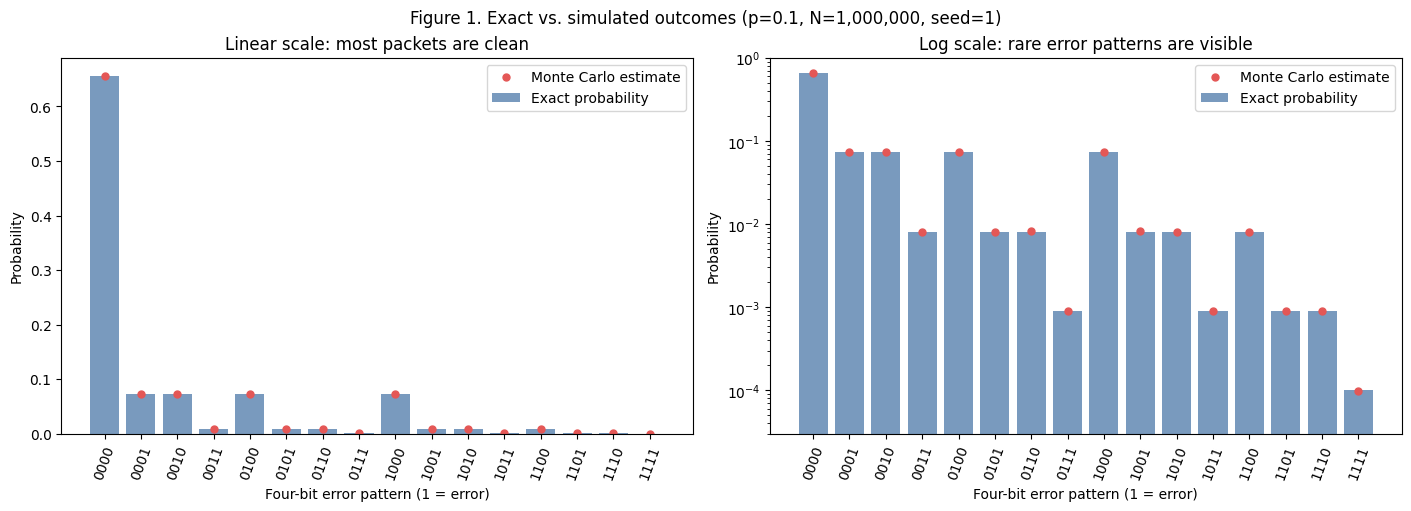

In [9]:
pattern_se = np.sqrt(exact_patterns*(1-exact_patterns)/N)
pattern_difference = empirical_patterns - exact_patterns
outcome_comparison = pd.DataFrame({
    "Pattern": labels, "Count": observed_counts,
    "Exact": exact_patterns, "Estimated": empirical_patterns,
    "Difference": pattern_difference, "SE": pattern_se,
    "Abs difference / SE": np.abs(pattern_difference)/pattern_se,
    "Within 3 SE": np.abs(pattern_difference) <= 3*pattern_se,
})
print(outcome_comparison.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
positions = np.arange(16)
for ax in axes:
    ax.bar(positions, exact_patterns, label="Exact probability", color="#4c78a8", alpha=0.75)
    ax.plot(positions, empirical_patterns, "o", label="Monte Carlo estimate",
            color="#e45756", markersize=5)
    ax.set_xticks(positions, labels, rotation=70)
    ax.set_xlabel("Four-bit error pattern (1 = error)")
    ax.set_ylabel("Probability")
    ax.legend()
axes[0].set_title("Linear scale: most packets are clean")
axes[1].set_yscale("log")
axes[1].set_ylim(0.00003, 1)
axes[1].set_title("Log scale: rare error patterns are visible")
fig.suptitle(f"Figure 1. Exact vs. simulated outcomes (p={p}, N={N:,}, seed={SEED})")
plt.show()

### Figure 1 interpretation

The clean pattern 0000 has the highest probability because every bit is more
likely to be correct than wrong. Changing a correct position to an error
changes one factor from 0.9 to 0.1. This makes that particular pattern nine
times less likely for each additional error. Patterns with the same error
count have equal exact probabilities. Their simulated frequencies vary slightly because we used a limited number
of random trials. The panel with a logarithmic axis makes the rare patterns easier to see.
Equal vertical spacing on that axis means equal ratios rather than equal
probability differences. The tables show the differences and standard errors.

The paragraph below includes numbers from the current run. Rerun from the top after changing the seed to update it.

In [10]:
union_row = comparison.iloc[-1]
worst_event = comparison.loc[comparison["Abs difference / SE"].idxmax()]
worst_pattern = outcome_comparison.loc[outcome_comparison["Abs difference / SE"].idxmax()]
event_status = "All eight" if comparison["Within 3 SE"].all() else "Not all eight"
pattern_status = "All 16" if outcome_comparison["Within 3 SE"].all() else "Not all 16"
interpretation = (
    f"The clean pattern 0000 is the most likely. Its exact probability is **0.6561**, "
    f"and its simulated estimate is **{empirical_patterns[0]:.6f}**, "
    f"a difference of **{pattern_difference[0]:+.6f}** with SE "
    f"**{pattern_se[0]:.6f}**. Each particular pattern becomes less likely as "
    f"its error count increases. The right panel uses a logarithmic y axis "
    f"to make rare outcomes easier to see. Equal vertical spacing represents equal "
    f"ratios rather than equal probability differences. {pattern_status} "
    f"outcome comparisons are within three SE. The largest difference is "
    f"**{worst_pattern['Abs difference / SE']:.3f} SE** for pattern "
    f"**{worst_pattern['Pattern']}**. {event_status} event and union comparisons "
    f"are within three SE. The largest event difference is "
    f"**{worst_event['Abs difference / SE']:.3f} SE** for "
    f"**{worst_event['Event']}**. The union estimate is "
    f"**{union_row['Estimated']:.6f}** compared with theory **0.271000**, "
    f"an absolute difference of **{abs(union_row['Difference']):.6f}**, "
    f"or **{union_row['Abs difference / SE']:.3f} SE**, with SE "
    f"**{union_row['SE']:.6f}**. Direct counting and empirical "
    f"inclusion–exclusion agree to within "
    f"**{abs(inclusion_exclusion_empirical-direct_union_empirical):.3e}**."
)
display(Markdown(interpretation))
runtime_seconds = time.perf_counter() - started
print(f"Step 1 runtime: {runtime_seconds:.3f} seconds")

The clean pattern 0000 is the most likely. Its exact probability is **0.6561**, and its simulated estimate is **0.655609**, a difference of **-0.000491** with SE **0.000475**. Each particular pattern becomes less likely as its error count increases. The right panel uses a logarithmic y axis to make rare outcomes easier to see. Equal vertical spacing represents equal ratios rather than equal probability differences. All 16 outcome comparisons are within three SE. The largest difference is **1.618 SE** for pattern **1001**. All eight event and union comparisons are within three SE. The largest event difference is **1.527 SE** for **A**. The union estimate is **0.271552** compared with theory **0.271000**, an absolute difference of **0.000552**, or **1.242 SE**, with SE **0.000444**. Direct counting and empirical inclusion–exclusion agree to within **0.000e+00**.

Step 1 runtime: 1.102 seconds


## Step 2: Conditional probability and Bayes

Let $E$ mean a bit is actually wrong and $F$ mean the circuit flags it.
The detector probabilities and the prior error probability are
$$P(F\mid E)=0.95,\qquad P(F\mid E^c)=0.02,\qquad P(E)=p.$$
Therefore $P(E^c)=1-p$. The detector's sensitivity is 95%, meaning it flags 95% of wrong bits.
We still need to find the probability that a flagged bit is actually wrong.

### Derive the posterior

The joint probability of a flag and an actual error is
$$P(F\cap E)=P(F\mid E)P(E)=0.95p.$$
A flag can come from a wrong bit or a correct bit. A bit cannot be both,
and these are the only two possibilities. The law of total probability gives
$$\begin{aligned}
P(F)&=P(F\mid E)P(E)+P(F\mid E^c)P(E^c)\\
    &=0.95p+0.02(1-p).
\end{aligned}$$
Using conditional probability gives Bayes' posterior, the probability
that a bit is wrong given that it was flagged:
$$\begin{aligned}
P(E\mid F)&=\frac{P(E\cap F)}{P(F)}\\
          &=\frac{P(F\mid E)P(E)}{P(F\mid E)P(E)+P(F\mid E^c)P(E^c)}\\
          &=\boxed{\frac{0.95p}{0.95p+0.02(1-p)}}.
\end{aligned}$$

This is flags for real errors divided by all flags. For example, among
100,000 bits at $p=0.001$, we expect 100 wrong bits and 99,900 correct bits.
We then expect 95 flags for real errors and 1,998 false alarms, giving
$95/(95+1998)=0.045389\ldots$.

In [11]:
sensitivity2 = 0.95
false_alarm_rate2 = 0.02
p_cases2 = np.array([0.1, 0.01, 0.001])
posterior_cases2 = sensitivity2*p_cases2 / (
    sensitivity2*p_cases2 + false_alarm_rate2*(1-p_cases2)
)
bayes_cases2 = pd.DataFrame({
    "Prior p": p_cases2,
    "P(error | flag)": posterior_cases2,
    "Posterior percent": 100*posterior_cases2,
})
print(bayes_cases2.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

 Prior p  P(error | flag)  Posterior percent
0.100000         0.840708          84.070796
0.010000         0.324232          32.423208
0.001000         0.045389           4.538939


### Find the 50% crossover analytically

Set the posterior to one half and solve for p. Keep the full value for
the simulation:
$$\begin{aligned}
\frac{0.95p}{0.95p+0.02(1-p)}&=\frac12\\
2(0.95p)&=0.95p+0.02(1-p)\\
0.95p&=0.02(1-p)\\
0.95p&=0.02-0.02p\\
0.97p&=0.02\\
p_*&=\frac{0.02}{0.97}=0.0206185567\ldots.
\end{aligned}$$
To three significant figures, report $\boxed{p_*=0.0206}$, or 2.06%.
At the crossover, a flag is equally likely to be a real error or a false alarm.
The total probability of a flag is
$$P(F)=0.95p_*+0.02(1-p_*)=0.0391752577\ldots,$$
so only about 3.92% of transmitted bits get flagged and enter the posterior
calculation.

In [12]:
crossover_p2 = false_alarm_rate2 / (sensitivity2 + false_alarm_rate2)
crossover_posterior2 = sensitivity2*crossover_p2 / (
    sensitivity2*crossover_p2 + false_alarm_rate2*(1-crossover_p2)
)
flag_probability2 = (sensitivity2*crossover_p2
                     + false_alarm_rate2*(1-crossover_p2))
print(f"Crossover p, full precision: {crossover_p2:.12f}")
print(f"Crossover p, three significant figures: {crossover_p2:.3g}")
print(f"Exact posterior at the crossover: {crossover_posterior2:.6f}")
print(f"Exact probability of getting a flag: {flag_probability2:.9f}")
assert np.isclose(crossover_posterior2, 0.5)

Crossover p, full precision: 0.020618556701
Crossover p, three significant figures: 0.0206
Exact posterior at the crossover: 0.500000
Exact probability of getting a flag: 0.039175258


### Verify the crossover with ten million bits

Use the separate Step 2 random generator. The BSC function simulates which
bits are wrong. Another random draw for each bit simulates the flagging
circuit. A wrong bit is flagged with probability 0.95, and a correct bit is
flagged with probability 0.02.

The posterior estimate uses only the flagged group:
$$\hat r=\frac{N_{F\cap E}}{N_F},\qquad
  N_F=N_{F\cap E}+N_{F\cap E^c}.$$
Once the flag count $N_F$ is known, each flagged bit is an independent
Bernoulli trial with two outcomes, actually wrong or actually correct. The estimated standard error of the ratio is
$$\widehat{SE}(\hat r)=\sqrt{\frac{\hat r(1-\hat r)}{N_F}}.$$
The denominator here is the actual flag count, not ten million. We compare the estimate with the theoretical posterior of 0.5 and report
the difference, the standard error, and how many standard errors apart they are.

In [13]:
rng_step2 = rng_steps[1]
N_bits2 = 10**7
actual_errors2 = bsc(np.zeros(N_bits2, dtype=np.uint8),
                     crossover_p2, rng_step2).astype(bool)
flag_probabilities2 = np.where(actual_errors2, sensitivity2, false_alarm_rate2)
flags2 = rng_step2.random(N_bits2) < flag_probabilities2
del flag_probabilities2

n_actual_errors2 = int(actual_errors2.sum())
n_flags2 = int(flags2.sum())
n_true_flags2 = int((flags2 & actual_errors2).sum())
n_false_flags2 = int((flags2 & ~actual_errors2).sum())
assert n_flags2 == n_true_flags2 + n_false_flags2
assert n_flags2 > 0

posterior_estimate2 = n_true_flags2 / n_flags2
posterior_se2 = np.sqrt(posterior_estimate2*(1-posterior_estimate2)/n_flags2)
posterior_difference2 = posterior_estimate2 - crossover_posterior2
posterior_z2 = abs(posterior_difference2)/posterior_se2
counts2 = pd.DataFrame({
    "Quantity": ["Transmitted bits", "Actually wrong bits", "Real-error flags",
                 "False alarms", "All flags"],
    "Count": [N_bits2, n_actual_errors2, n_true_flags2, n_false_flags2, n_flags2],
})
print(counts2.to_string(index=False))
print(f"Actual flagged fraction: {n_flags2/N_bits2:.9f}")
print(f"Expected flagged fraction: {flag_probability2:.9f}")
comparison2 = pd.DataFrame([{
    "Exact posterior": crossover_posterior2,
    "Estimated posterior": posterior_estimate2,
    "Difference": posterior_difference2,
    "Ratio SE": posterior_se2,
    "Abs difference / SE": posterior_z2,
    "Within 3 SE": bool(posterior_z2 <= 3),
}])
print("\nCrossover posterior comparison:")
print(comparison2.to_string(index=False, float_format=lambda x: f"{x:.9f}"))
del actual_errors2, flags2

           Quantity    Count
   Transmitted bits 10000000
Actually wrong bits   207091
   Real-error flags   196765
       False alarms   195712
          All flags   392477
Actual flagged fraction: 0.039247700
Expected flagged fraction: 0.039175258

Crossover posterior comparison:
 Exact posterior  Estimated posterior  Difference    Ratio SE  Abs difference / SE  Within 3 SE
     0.500000000          0.501341480 0.001341480 0.000798107          1.680826276         True


### Figure 2: posterior versus prior

Use 200 prior values spaced evenly on a logarithmic scale from 10^-4 to
10^-1. Mark the exact crossover and add the simulated estimate with an error
bar showing plus or minus one standard error. The error bar is small because the simulation is large.

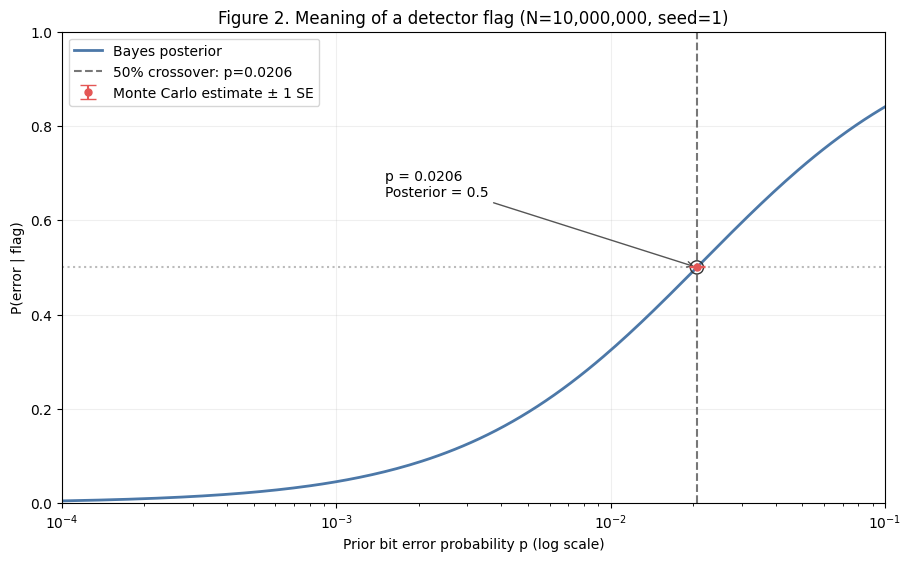

In [14]:
p_grid2 = np.logspace(-4, -1, 200)
posterior_grid2 = sensitivity2*p_grid2 / (
    sensitivity2*p_grid2 + false_alarm_rate2*(1-p_grid2)
)
assert len(p_grid2) == 200
fig2, ax2 = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax2.plot(p_grid2, posterior_grid2, color="#4c78a8", linewidth=2,
         label="Bayes posterior")
ax2.axvline(crossover_p2, color="#777777", linestyle="--",
            label=f"50% crossover: p={crossover_p2:.3g}")
ax2.axhline(0.5, color="#bbbbbb", linestyle=":")
ax2.scatter([crossover_p2], [0.5], s=90, facecolors="none",
            edgecolors="#333333", zorder=4)
ax2.errorbar([crossover_p2], [posterior_estimate2], yerr=[posterior_se2],
            fmt="o", color="#e45756", capsize=6, markersize=5,
            label="Monte Carlo estimate ± 1 SE", zorder=5)
ax2.annotate(f"p = {crossover_p2:.3g}\nPosterior = 0.5",
             xy=(crossover_p2, 0.5), xytext=(0.0015, 0.65),
             arrowprops={"arrowstyle": "->", "color": "#555555"})
ax2.set_xscale("log")
ax2.set_xlim(1e-4, 1e-1)
ax2.set_ylim(0, 1)
ax2.set_xlabel("Prior bit error probability p (log scale)")
ax2.set_ylabel("P(error | flag)")
ax2.set_title(f"Figure 2. Meaning of a detector flag (N={N_bits2:,}, seed={SEED})")
ax2.grid(alpha=0.2)
ax2.legend(loc="upper left")
plt.show()

### Figure 2 interpretation

A flag is more likely to mean a real error as the prior error probability
increases. When errors are rare, there are so many correct bits that false
alarms make up most of the flagged group. At p=0.001, a
flag indicates a real error only about 4.54% of the time, despite the 95%
sensitivity. At p=0.1 that posterior rises to about 84.07%. The curve crosses
0.5 at p=0.0206. The Monte Carlo point and its error bar let us check the posterior at the
crossover. The difference is too small to see clearly on this graph, so the
table and the paragraph below report its value and standard error.

### Explanation for a manager

On a link where only 0.1% of bits are wrong, about 4.54% of the circuit's flags
indicate real errors. The circuit detects 95% of wrong bits, but its 2%
false alarm rate applies to a much larger number of correct bits, so false
alarms greatly outnumber flags for real errors. The meaning of a flag therefore
depends on the link's error rate, not just the detector's sensitivity.

In [15]:
display(Markdown(
    f"At the crossover **p = {crossover_p2:.12f}**, the simulation generated "
    f"**{n_flags2:,} flags** out of **{N_bits2:,} bits**, including "
    f"**{n_true_flags2:,} flags for real errors** and **{n_false_flags2:,} false alarms**. "
    f"The posterior estimate is **{posterior_estimate2:.9f}**, compared with "
    f"the exact value **0.500000000**. The estimate minus theory is "
    f"**{posterior_difference2:+.9f}**, with an estimated ratio standard error "
    f"of **{posterior_se2:.9f}**. The difference is **{posterior_z2:.3f} SE**. "
    f"This {'is' if posterior_z2 <= 3 else 'is not'} within three SE."
))
checkpoint_runtime = time.perf_counter() - started
print(f"Steps 1–2 checkpoint runtime: {checkpoint_runtime:.3f} seconds")

At the crossover **p = 0.020618556701**, the simulation generated **392,477 flags** out of **10,000,000 bits**, including **196,765 flags for real errors** and **195,712 false alarms**. The posterior estimate is **0.501341480**, compared with the exact value **0.500000000**. The estimate minus theory is **+0.001341480**, with an estimated ratio standard error of **0.000798107**. The difference is **1.681 SE**. This is within three SE.

Steps 1–2 checkpoint runtime: 1.808 seconds


## Step 3: Independence

### Part 1: pairwise independence does not imply mutual independence

Two independent fair coins have four equally likely outcomes:

| Outcome | $E_1$: first heads | $E_2$: second heads | $E_3$: coins match |
|---|---|---|---|
| HH | Yes | Yes | Yes |
| HT | Yes | No | No |
| TH | No | Yes | No |
| TT | No | No | Yes |

Each event occurs in two outcomes, so $P(E_1)=P(E_2)=P(E_3)=2/4=1/2$.
For each pair of events, HH is the only outcome where both happen. This gives
$$\begin{aligned}
P(E_1\cap E_2)&=1/4=(1/2)(1/2)=P(E_1)P(E_2),\\
P(E_1\cap E_3)&=1/4=(1/2)(1/2)=P(E_1)P(E_3),\\
P(E_2\cap E_3)&=1/4=(1/2)(1/2)=P(E_2)P(E_3).
\end{aligned}$$
Every pair passes, proving **pairwise independence**. For all three,
$$P(E_1\cap E_2\cap E_3)=P(\{HH\})=1/4,$$
while
$$P(E_1)P(E_2)P(E_3)=(1/2)^3=1/8.$$
The difference is $1/4-1/8=1/8$, so **mutual independence fails**.
Another way to see this is that knowing both coins are heads means
they must match:
$P(E_3\mid E_1\cap E_2)=1$, compared with $P(E_3)=1/2$.

#### Standard errors for the numerical comparisons

Simulate $10^6$ coin pairs. For a set of event indices $S$, let
$I_{ik}=1$ if event $E_i$ happens in trial $k$, and zero otherwise.
Let $\hat p_i=N^{-1}\sum_k I_{ik}$, $J_k=\prod_{i\in S}I_{ik}$,
$\hat j=N^{-1}\sum_k J_k$, and $\hat m=\prod_{i\in S}\hat p_i$.
The table compares the estimated joint probability with the product
of the estimated event probabilities:
$\hat D=\hat j-\hat m$. These estimates use the same coin trials, so their
estimation errors are related. A first-order expansion gives
$$\begin{aligned}
\hat m-m&\approx\sum_{i\in S}\left(\prod_{\ell\in S,\ell\ne i}p_\ell\right)(\hat p_i-p_i),\\
\hat D-D&\approx N^{-1}\sum_k h_k,\\
h_k&=(J_k-\hat j)-\sum_{i\in S}\left(\prod_{\ell\in S,\ell\ne i}\hat p_\ell\right)(I_{ik}-\hat p_i),\\
\widehat{SE}(\hat D)&=\frac{s_h}{\sqrt N},\qquad
s_h^2=\frac{1}{N-1}\sum_k(h_k-\bar h)^2.
\end{aligned}$$
This includes the effect of using the same samples. The joint estimate
also has its own
binomial SE $\sqrt{j(1-j)/N}$, using the known exact $j=1/4$.
The table shows how far the joint estimates are from theory and how far
they are from the products. Theory gives a zero gap for each pair and a
gap of 0.125 for all three events together.

In [16]:
rng_step3 = rng_steps[2]
N_coins3 = 10**6
coins3 = rng_step3.integers(0, 2, size=(N_coins3, 2), dtype=np.uint8)
events3 = np.column_stack((coins3[:, 0] == 1,
                           coins3[:, 1] == 1,
                           coins3[:, 0] == coins3[:, 1])).astype(float)
event_rates3 = events3.mean(axis=0)
coin_rows3 = []
for label3, indices3 in [("E1 & E2", (0, 1)), ("E1 & E3", (0, 2)),
                         ("E2 & E3", (1, 2)), ("E1 & E2 & E3", (0, 1, 2))]:
    joint_indicator3 = np.prod(events3[:, indices3], axis=1)
    joint_estimate3 = joint_indicator3.mean()
    product_estimate3 = np.prod(event_rates3[list(indices3)])
    joint_exact3 = 0.25
    product_exact3 = 0.5**len(indices3)
    gap_exact3 = joint_exact3 - product_exact3
    gap_estimate3 = joint_estimate3 - product_estimate3
    gap_influence3 = joint_indicator3 - joint_estimate3
    for index3 in indices3:
        other_product3 = np.prod([event_rates3[i] for i in indices3 if i != index3])
        gap_influence3 -= other_product3*(events3[:, index3]-event_rates3[index3])
    gap_se3 = gap_influence3.std(ddof=1)/np.sqrt(N_coins3)
    joint_se3 = np.sqrt(joint_exact3*(1-joint_exact3)/N_coins3)
    coin_rows3.append({
        "Events": label3, "Exact product": product_exact3,
        "Empirical product": product_estimate3, "Exact joint": joint_exact3,
        "Empirical joint": joint_estimate3,
        "Joint - theory": joint_estimate3-joint_exact3, "Joint SE": joint_se3,
        "Joint - product": gap_estimate3, "Gap SE": gap_se3,
        "Gap - exact gap": gap_estimate3-gap_exact3,
        "Gap discrepancy / SE": abs(gap_estimate3-gap_exact3)/gap_se3,
    })
coin_table3 = pd.DataFrame(coin_rows3)
assert N_coins3 == 10**6
assert np.isclose(coin_table3.iloc[-1]["Exact joint"]
                  - coin_table3.iloc[-1]["Exact product"], 0.125)
print("Table 3A. Coin independence checks (N = 1,000,000)")
print("Empirical event probabilities:",
      ", ".join(f"P(E{i+1})={v:.9f}" for i, v in enumerate(event_rates3)))
print(coin_table3.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

Table 3A. Coin independence checks (N = 1,000,000)
Empirical event probabilities: P(E1)=0.499779000, P(E2)=0.500838000, P(E3)=0.500069000
      Events  Exact product  Empirical product  Exact joint  Empirical joint  Joint - theory    Joint SE  Joint - product      Gap SE  Gap - exact gap  Gap discrepancy / SE
     E1 & E2    0.250000000        0.250308315  0.250000000      0.250343000     0.000343000 0.000433013      0.000034685 0.000250000      0.000034685           0.138740932
     E1 & E3    0.250000000        0.249923985  0.250000000      0.250343000     0.000343000 0.000433013      0.000419015 0.000250000      0.000419015           1.676062692
     E2 & E3    0.250000000        0.250453558  0.250000000      0.250343000     0.000343000 0.000433013     -0.000110558 0.000250000     -0.000110558           0.442231736
E1 & E2 & E3    0.125000000        0.125171429  0.250000000      0.250343000     0.000343000 0.000433013      0.125171571 0.000216407      0.000171571           0.7928170

In [17]:
pair_worst3 = coin_table3.iloc[:3]["Gap discrepancy / SE"].max()
triple_row3 = coin_table3.iloc[-1]
joint_worst3 = (abs(coin_table3["Joint - theory"])/coin_table3["Joint SE"]).max()
display(Markdown(
    f"The largest difference between a pairwise joint probability and its product is **{pair_worst3:.3f} SE** "
    f"from the expected gap of zero. For all three events, the estimated joint probability is "
    f"**{triple_row3['Empirical joint']:.9f}**, while the product of the estimated event probabilities is "
    f"**{triple_row3['Empirical product']:.9f}**. Their gap is "
    f"**{triple_row3['Joint - product']:.9f}**, with gap SE "
    f"**{triple_row3['Gap SE']:.9f}**. It differs from the exact gap **0.125** by "
    f"**{triple_row3['Gap - exact gap']:+.9f}**, or "
    f"**{triple_row3['Gap discrepancy / SE']:.3f} SE**. "
    f"All joint estimates are within **{joint_worst3:.3f} SE** of their exact values. "
    "The exact calculations show pairwise independence but rule out mutual independence. "
    "The simulation shows the small differences caused by random sampling."
))

The largest difference between a pairwise joint probability and its product is **1.676 SE** from the expected gap of zero. For all three events, the estimated joint probability is **0.250343000**, while the product of the estimated event probabilities is **0.125171429**. Their gap is **0.125171571**, with gap SE **0.000216407**. It differs from the exact gap **0.125** by **+0.000171571**, or **0.793 SE**. All joint estimates are within **0.792 SE** of their exact values. The exact calculations show pairwise independence but rule out mutual independence. The simulation shows the small differences caused by random sampling.

### Part 2: receivers with a shared transmitted bit

Let $T$ be the transmitted bit, with $P(T=0)=P(T=1)=1/2$.
Receiver outputs $X$ and $Y$ use independent BSC errors with probabilities
$p_1=0.1$ and $p_2=0.3$. Both receivers listen directly to the transmitter.
Their errors are independent, but both output values depend on $T$.

#### Unconditional dependence

Using the law of total probability, each receiver has a 50% chance
of outputting 1:
$$\begin{aligned}
P(X=1)&=\tfrac12(0.9)+\tfrac12(0.1)=\tfrac12,\\
P(Y=1)&=\tfrac12(0.7)+\tfrac12(0.3)=\tfrac12.
\end{aligned}$$
Since the outputs are 0 or 1, $XY=1$ only when both outputs are 1:
$$\begin{aligned}
E[XY]&=P(X=1,Y=1)\\
     &=P(T=1)(0.9)(0.7)+P(T=0)(0.1)(0.3)\\
     &=0.5(0.63)+0.5(0.03)=0.33,\\
\operatorname{Cov}(X,Y)&=E[XY]-E[X]E[Y]=0.33-0.25=0.08,\\
\operatorname{Var}(X)&=\operatorname{Var}(Y)=0.5(1-0.5)=0.25,\\
\rho_{XY}&=\frac{0.08}{\sqrt{0.25(0.25)}}=\boxed{0.32}.
\end{aligned}$$
The covariance is not zero, so the outputs are dependent. We can also check
$P(Y=1\mid X=1)=0.33/0.5=0.66$, compared with $P(Y=1)=0.5$.

#### Conditional independence

If $T=0$, an output of 1 means that receiver made an error. The errors
are independent, so
$$P(X=1,Y=1\mid T=0)=0.1(0.3)=0.03
  =P(X=1\mid T=0)P(Y=1\mid T=0).$$
If $T=1$, output 1 means no error:
$$P(X=1,Y=1\mid T=1)=0.9(0.7)=0.63
  =P(X=1\mid T=1)P(Y=1\mid T=1).$$
The other three output combinations work the same way because the channel
errors are independent. So $X$ and $Y$ are independent once either value of
$T$ is known. Their conditional covariances and correlations are zero.
For either value, the conditional variances are $0.1(0.9)=0.09$ and
$0.3(0.7)=0.21$, so the correlations are defined.

When the original bit is unknown, one receiver gives us a clue about what
was sent. That helps us predict the other receiver. Once the original bit is
known, receiver 2 stays 70% accurate whether receiver 1 is right or wrong.
Zero correlation does not always mean independence. Here, independence
follows from knowing the original bit and having independent channel errors.

#### Pearson correlation and its standard error

For each group of $n$ transmissions, subtract the mean from each output:
$u_k=X_k-\bar X$, $v_k=Y_k-\bar Y$. Define
$$a=\frac1n\sum_k u_k^2,\quad b=\frac1n\sum_k v_k^2,\quad
  c=\frac1n\sum_k u_kv_k,\quad \hat r=\frac{c}{\sqrt{ab}}.$$
A first-order expansion of $r=c/\sqrt{ab}$ gives
$$dr=\frac{dc}{\sqrt{ab}}-\frac{r}{2}\left(\frac{da}{a}+\frac{db}{b}\right).$$
Using the contribution from each transmission gives
$$\begin{aligned}
h_k&=\frac{u_kv_k-c}{\sqrt{ab}}-
  \frac{\hat r}{2}\left(\frac{u_k^2-a}{a}+\frac{v_k^2-b}{b}\right)\\
   &=\frac{u_kv_k}{\sqrt{ab}}-
  \frac{\hat r}{2}\left(\frac{u_k^2}{a}+\frac{v_k^2}{b}\right),\\
\widehat{SE}(\hat r)&=\frac{s_h}{\sqrt n}.
\end{aligned}$$
This delta-method estimate works for a large sample of independent
transmissions with binary outputs. It does not assume the outputs follow a
normal distribution. We use the same formula for each conditional group,
with that group's sample size, means, variances, and covariance.

Method reference: [Pearson correlation influence function, Proposition 2](https://www.mdpi.com/2227-7390/10/17/3100).
The steps above show how the formula applies after subtracting the means
and scaling by the standard deviations.

In [18]:
N_transmissions3 = 10**6
transmitted3 = rng_step3.integers(0, 2, size=N_transmissions3, dtype=np.uint8)
receiver1_3 = bsc(transmitted3, 0.1, rng_step3)
receiver2_3 = bsc(transmitted3, 0.3, rng_step3)
receiver_rows3 = []
for group3, mask3, theory3 in [
    ("All transmissions", np.ones(N_transmissions3, dtype=bool), 0.32),
    ("Transmitted bit = 0", transmitted3 == 0, 0.0),
    ("Transmitted bit = 1", transmitted3 == 1, 0.0),
]:
    x3 = receiver1_3[mask3].astype(float)
    y3 = receiver2_3[mask3].astype(float)
    n_group3 = len(x3)
    assert n_group3 >= 10**5
    u3, v3 = x3-x3.mean(), y3-y3.mean()
    a3, b3 = np.mean(u3*u3), np.mean(v3*v3)
    c3 = np.mean(u3*v3)
    assert a3 > 0 and b3 > 0
    correlation3 = c3/np.sqrt(a3*b3)
    influence3 = u3*v3/np.sqrt(a3*b3) - 0.5*correlation3*(u3*u3/a3 + v3*v3/b3)
    correlation_se3 = influence3.std(ddof=1)/np.sqrt(n_group3)
    # Independent check of the Pearson calculation, not a new random draw.
    assert np.isclose(correlation3, np.corrcoef(x3, y3)[0, 1])
    difference3 = correlation3-theory3
    receiver_rows3.append({
        "Group": group3, "N": n_group3, "Theory rho": theory3,
        "Pearson r": correlation3, "SE": correlation_se3,
        "Difference": difference3, "Abs difference / SE": abs(difference3)/correlation_se3,
        "Within 3 SE": bool(abs(difference3) <= 3*correlation_se3),
    })
receiver_table3 = pd.DataFrame(receiver_rows3)
assert int(receiver_table3.iloc[1:]["N"].sum()) == N_transmissions3
print("Table 3B. Receiver correlations (independent channel errors)")
print(receiver_table3.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

Table 3B. Receiver correlations (independent channel errors)
              Group       N  Theory rho   Pearson r          SE  Difference  Abs difference / SE  Within 3 SE
  All transmissions 1000000 0.320000000 0.320082885 0.000947389 0.000082885          0.087487871         True
Transmitted bit = 0  500409 0.000000000 0.001977011 0.001416835 0.001977011          1.395371926         True
Transmitted bit = 1  499591 0.000000000 0.000704650 0.001415953 0.000704650          0.497650486         True


In [19]:
all_row3 = receiver_table3.iloc[0]
zero_row3 = receiver_table3.iloc[1]
one_row3 = receiver_table3.iloc[2]
display(Markdown(
    f"Across all **{N_transmissions3:,} transmissions**, the receiver correlation "
    f"is **{all_row3['Pearson r']:.9f}**, compared with theory **0.32**. The difference "
    f"is **{all_row3['Difference']:+.9f}**, with SE **{all_row3['SE']:.9f}** "
    f"(**{all_row3['Abs difference / SE']:.3f} SE**). "
    f"For the **{int(zero_row3['N']):,} transmissions where the original bit was zero**, the "
    f"correlation is **{zero_row3['Pearson r']:+.9f}**, with SE "
    f"**{zero_row3['SE']:.9f}** (**{zero_row3['Abs difference / SE']:.3f} SE** from zero). "
    f"For the **{int(one_row3['N']):,} transmissions where the original bit was one**, it is "
    f"**{one_row3['Pearson r']:+.9f}**, with SE **{one_row3['SE']:.9f}** "
    f"(**{one_row3['Abs difference / SE']:.3f} SE** from zero). "
    "The outputs are dependent overall but independent once the original bit is known."
))

Across all **1,000,000 transmissions**, the receiver correlation is **0.320082885**, compared with theory **0.32**. The difference is **+0.000082885**, with SE **0.000947389** (**0.087 SE**). For the **500,409 transmissions where the original bit was zero**, the correlation is **+0.001977011**, with SE **0.001416835** (**1.395 SE** from zero). For the **499,591 transmissions where the original bit was one**, it is **+0.000704650**, with SE **0.001415953** (**0.498 SE** from zero). The outputs are dependent overall but independent once the original bit is known.

### Part 3: sensor-fusion consequence

If a system assumes positively dependent sensor readings with a shared cause
are independent, it can count the same information twice and become too
confident in its estimates.

## Step 4: Bernoulli trials and the Binomial
Each bit error is a Bernoulli trial because each bit either is corrupted or is not corrupted.
Because the bits are independent and all have the same error probability p, the total number
of errors in a packet of n bits follows a Binomial distribution:

$$X \sim \operatorname{Binomial}(n,p)$$

The theoretical mean and variance are

$$E[X]=np$$

$$\operatorname{Var}(X)=np(1-p).$$

In [20]:
# Step 4: packet-level Binomial behavior
rng_step4 = rng_steps[3]

n_pkt4 = 10**5
n_bits4 = 1000
p4 = 0.005

errors4 = packet_errors(n_pkt4, n_bits4, p4, rng_step4)

print(f"Simulated packets: {n_pkt4:,}")
print(f"Sample mean: {errors4.mean():.6f}")
print(f"Sample variance: {errors4.var(ddof=1):.6f}")

theory_mean4 = n_bits4 * p4
theory_variance4 = n_bits4 * p4 * (1 - p4)

print(f"Theoretical mean: {theory_mean4:.6f}")
print(f"Theoretical variance: {theory_variance4:.6f}")
print(f"Mean difference: {errors4.mean() - theory_mean4:+.6f}")
print(f"Variance difference: {errors4.var(ddof=1) - theory_variance4:+.6f}")

Simulated packets: 100,000
Sample mean: 5.001810
Sample variance: 4.979917
Theoretical mean: 5.000000
Theoretical variance: 4.975000
Mean difference: +0.001810
Variance difference: +0.004917


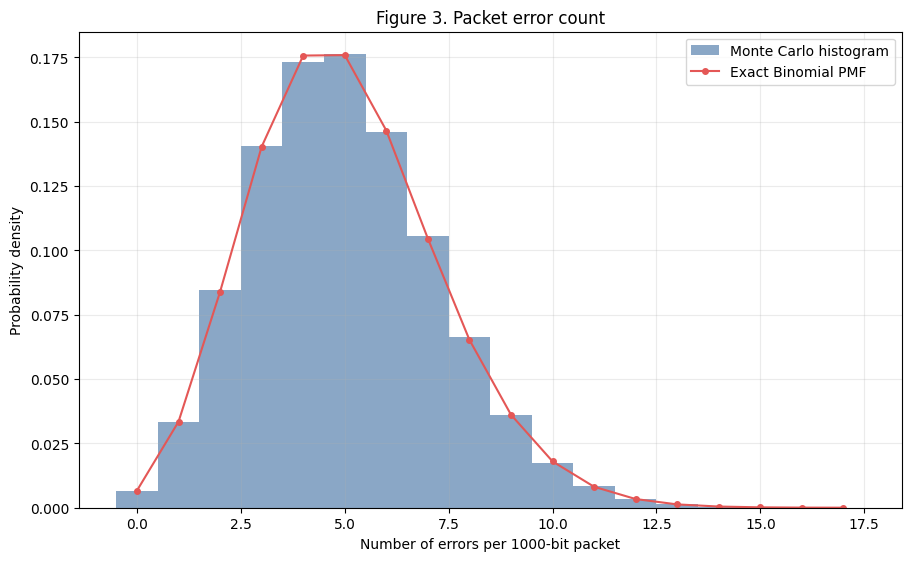

In [21]:
# Creating error count histogram 
max_error4 = errors4.max()
k4 = np.arange(0, max_error4 + 1)

fig3, ax3 = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

ax3.hist(
    errors4,
    bins=np.arange(-0.5, max_error4 + 1.5, 1),
    density=True,
    alpha=0.65,
    color="#4c78a8",
    label="Monte Carlo histogram"
)

ax3.plot(
    k4,
    binom.pmf(k4, n_bits4, p4),
    "o-",
    color="#e45756",
    markersize=4,
    label="Exact Binomial PMF"
)

ax3.set_xlabel("Number of errors per 1000-bit packet")
ax3.set_ylabel("Probability density")
ax3.set_title("Figure 3. Packet error count")
ax3.legend()
ax3.grid(alpha=0.25)

plt.show()

In [22]:
# Comparing clean-packet probabilities
clean_p_values4 = [0.005, 0.001, 0.0001]
clean_rows4 = []

for p_clean4 in clean_p_values4:
    simulated_errors4 = packet_errors(
        n_pkt4,
        n_bits4,
        p_clean4,
        rng_step4
    )

    empirical_clean4 = np.mean(simulated_errors4 == 0)
    exact_clean4 = (1 - p_clean4) ** n_bits4
    difference_clean4 = empirical_clean4 - exact_clean4

    clean_rows4.append({
        "p": p_clean4,
        "Exact P(clean)": exact_clean4,
        "Empirical P(clean)": empirical_clean4,
        "Difference": difference_clean4
    })

clean_table4 = pd.DataFrame(clean_rows4)
print(clean_table4.to_string(index=False, float_format=lambda x: f"{x:.9f}"))

          p  Exact P(clean)  Empirical P(clean)   Difference
0.005000000     0.006653969         0.006250000 -0.000403969
0.001000000     0.367695425         0.367070000 -0.000625425
0.000100000     0.904832894         0.905100000  0.000267106


### Step 4 Interpretation

The simulated histogram closely follows the exact Binomial PMF, confirming that the number of bit errors in each packet is well modeled by a Binomial distribution. The simulated mean and variance are close to the theoretical values,

$$
E[X] = np = 5
$$

and

$$
Var(X) = np(1-p) = 4.975.
$$

For \(p=0.005\), the probability that a 1000-bit packet is received without errors is approximately \(0.00665\), or \(0.665\%\). Thus, only a small fraction of packets arrive cleanly, meaning retransmissions would be very common at this bit-error rate. As the bit-error probability decreases, the probability of receiving a clean packet increases significantly.

## Step 5: Poisson Approximation

When $n$ is large and $p$ is small, a Binomial random variable can be approximated by a Poisson random variable with parameter $\lambda = np$.

The Binomial PMF is
$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k},
$$

while the Poisson PMF is
$$
P(Y=k)=e^{-\lambda}\frac{\lambda^k}{k!}.
$$

The total variation distance measures the difference between two PMFs:
$$
d_{\mathrm{TV}}(P,Q) = \frac{1}{2}\sum_k |P(k)-Q(k)|.
$$

A value of zero means the distributions are identical. A value of one means they have completely disjoint support.

In [23]:
# Compute Binomial and Poisson Distributions
rng_step5 = rng_steps[4]  # Reserved for Step 5

n5 = 1000
p_values5 = [0.5, 0.05, 0.005, 0.001, 0.0005]
tail_tolerance5 = 1e-12


def common_pmfs5(n, p, tail_tolerance=1e-12):
    """Return a common support and truncated Binomial/Poisson PMFs."""
    lam = n * p

    # Select K so that the omitted Poisson upper tail is below tolerance.
    K = int(poisson.ppf(1 - tail_tolerance, lam))

    while poisson.sf(K, lam) >= tail_tolerance:
        K += 1

    k = np.arange(K + 1)

    binomial_pmf = binom.pmf(k, n, p)
    poisson_pmf = poisson.pmf(k, lam)
    poisson_tail = poisson.sf(K, lam)

    return k, binomial_pmf, poisson_pmf, poisson_tail


step5_rows = []
step5_results = {}

for p5 in p_values5:
    k5, binomial_pmf5, poisson_pmf5, poisson_tail5 = common_pmfs5(
        n5,
        p5,
        tail_tolerance5
    )

    distance5 = tv_distance(binomial_pmf5, poisson_pmf5)

    step5_results[p5] = {
        "k": k5,
        "binomial": binomial_pmf5,
        "poisson": poisson_pmf5,
        "tail": poisson_tail5,
        "tv": distance5
    }

    step5_rows.append({
        "p": p5,
        "lambda": n5 * p5,
        "TV distance": distance5,
        "Poisson tail": poisson_tail5
    })

step5_table = pd.DataFrame(step5_rows)

print(
    step5_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6e}"
    )
)

           p       lambda  TV distance  Poisson tail
5.000000e-01 5.000000e+02 1.660573e-01  9.079137e-13
5.000000e-02 5.000000e+01 1.244598e-02  8.237578e-13
5.000000e-03 5.000000e+00 1.227570e-03  9.933985e-13
1.000000e-03 1.000000e+00 2.760706e-04  3.000011e-13
5.000000e-04 5.000000e-01 1.137711e-04  3.214697e-13


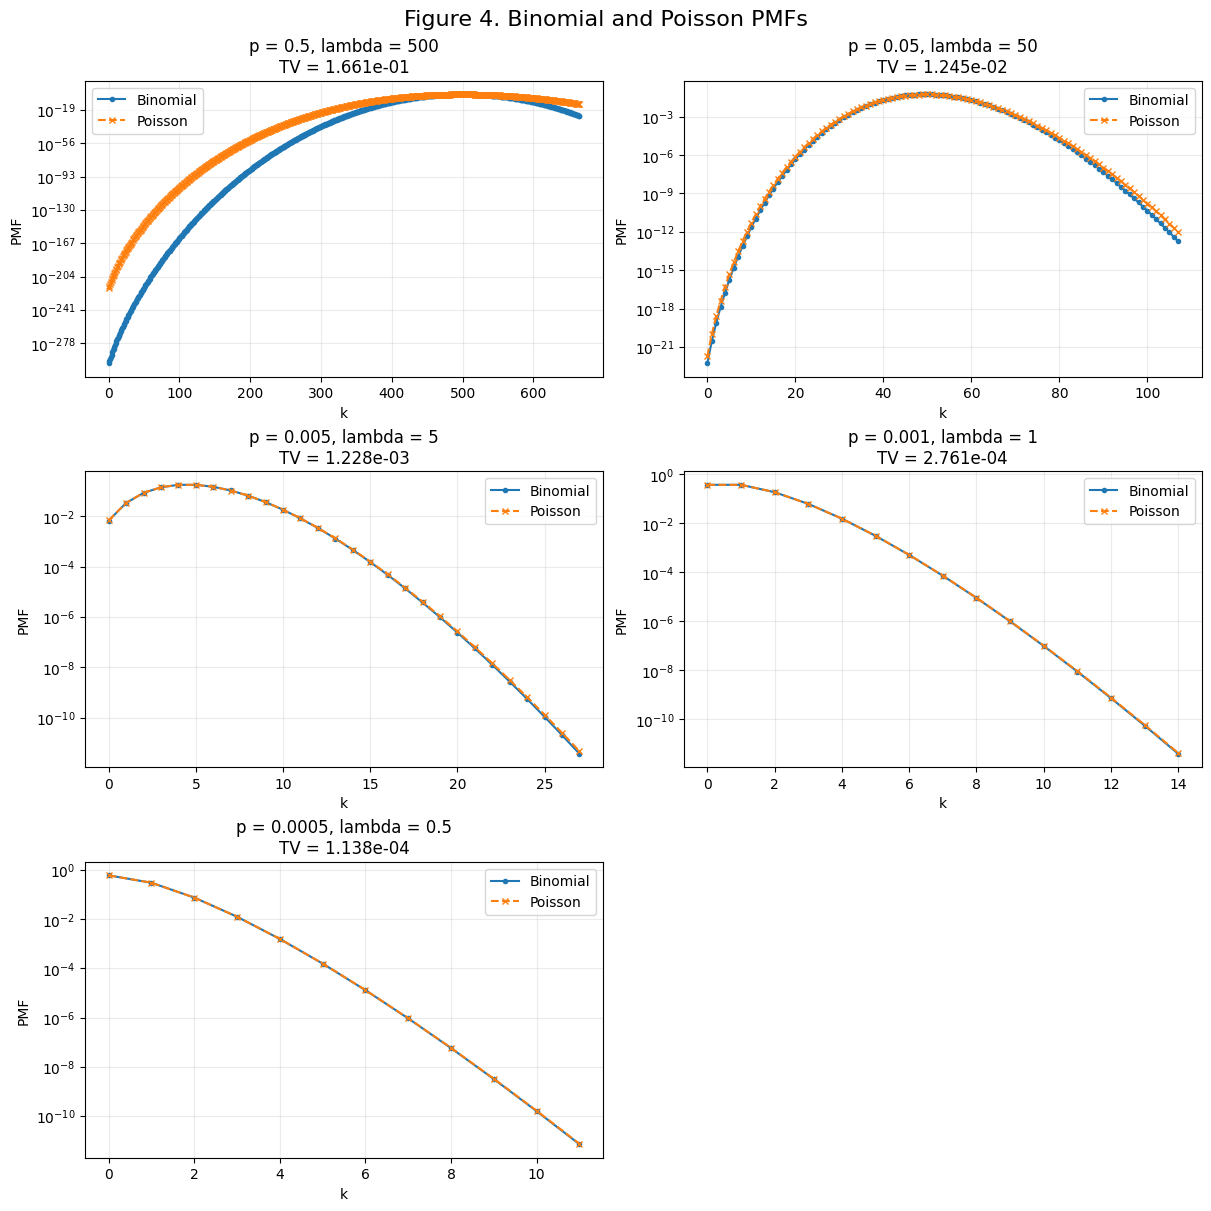

In [24]:
fig4, axes4 = plt.subplots(
    3,
    2,
    figsize=(12, 12),
    constrained_layout=True
)

axes4 = axes4.ravel()

for i, p5 in enumerate(p_values5):
    result5 = step5_results[p5]

    k5 = result5["k"]
    binomial_pmf5 = result5["binomial"]
    poisson_pmf5 = result5["poisson"]

    # Prevent zero values from causing issues on the log-scaled axis.
    binomial_plot5 = np.maximum(binomial_pmf5, 1e-300)
    poisson_plot5 = np.maximum(poisson_pmf5, 1e-300)

    axes4[i].plot(
        k5,
        binomial_plot5,
        "o-",
        markersize=3,
        label="Binomial"
    )

    axes4[i].plot(
        k5,
        poisson_plot5,
        "x--",
        markersize=4,
        label="Poisson"
    )

    axes4[i].set_yscale("log")
    axes4[i].set_xlabel("k")
    axes4[i].set_ylabel("PMF")
    axes4[i].set_title(
        f"p = {p5}, lambda = {n5 * p5:.3g}\n"
        f"TV = {result5['tv']:.3e}"
    )
    axes4[i].grid(alpha=0.25)
    axes4[i].legend()

# Hide the unused sixth subplot.
axes4[-1].axis("off")

fig4.suptitle(
    "Figure 4. Binomial and Poisson PMFs",
    fontsize=16
)

plt.show()

In [25]:
def tv_for_p5(p):
    """Calculate the TV distance for n=1000 and a selected p."""
    _, binomial_pmf, poisson_pmf, _ = common_pmfs5(
        n5,
        p,
        tail_tolerance5
    )
    return tv_distance(binomial_pmf, poisson_pmf)


# Verify that the distance generally increases with p.
p_check5 = np.linspace(0.001, 0.1, 100)
tv_check5 = np.array([tv_for_p5(p) for p in p_check5])

print("TV distance is increasing over the check grid:",
      np.all(np.diff(tv_check5) >= 0))

# Bisection for the largest p such that TV distance < 0.01.
p_low5 = 0.001
p_high5 = 0.1
tv_target5 = 0.01

while p_high5 - p_low5 > 1e-8:
    p_mid5 = 0.5 * (p_low5 + p_high5)

    if tv_for_p5(p_mid5) < tv_target5:
        p_low5 = p_mid5
    else:
        p_high5 = p_mid5

p_limit5 = p_low5
tv_limit5 = tv_for_p5(p_limit5)
le_cam_limit5 = n5 * p_limit5**2

print(f"Largest p with TV distance < 0.01: {p_limit5:.8f}")
print(f"TV distance at this p: {tv_limit5:.8f}")
print(f"Le Cam bound at this p: {le_cam_limit5:.8f}")
print(f"Le Cam threshold: {np.sqrt(0.01 / n5):.8f}")

TV distance is increasing over the check grid: True
Largest p with TV distance < 0.01: 0.04039359
TV distance at this p: 0.01000000
Le Cam bound at this p: 1.63164175
Le Cam threshold: 0.00316228


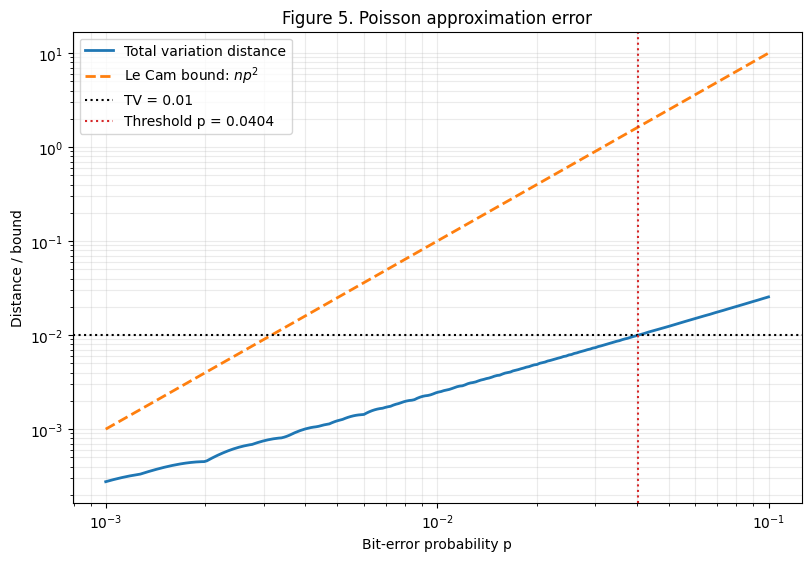

In [26]:
p_plot5 = np.logspace(np.log10(0.001), np.log10(0.1), 250)
tv_plot5 = np.array([tv_for_p5(p) for p in p_plot5])
le_cam_plot5 = n5 * p_plot5**2

fig5, ax5 = plt.subplots(figsize=(8, 5.5), constrained_layout=True)

ax5.loglog(
    p_plot5,
    tv_plot5,
    label="Total variation distance",
    linewidth=2
)

ax5.loglog(
    p_plot5,
    le_cam_plot5,
    "--",
    label=r"Le Cam bound: $np^2$",
    linewidth=2
)

ax5.axhline(
    0.01,
    color="black",
    linestyle=":",
    label="TV = 0.01"
)

ax5.axvline(
    p_limit5,
    color="tab:red",
    linestyle=":",
    label=f"Threshold p = {p_limit5:.4f}"
)

ax5.set_xlabel("Bit-error probability p")
ax5.set_ylabel("Distance / bound")
ax5.set_title("Figure 5. Poisson approximation error")
ax5.grid(True, which="both", alpha=0.25)
ax5.legend()

plt.show()

### Step 5 Interpretation

The Poisson approximation becomes more accurate as the bit-error probability $p$ decreases. This is shown by the decreasing total variation distance between the exact Binomial PMF and the Poisson PMF.

For $n=1000$, the Poisson approximation is most reliable when $p$ is small while the expected number of errors,
$$
\lambda=np,
$$
remains a reasonable event count. The total variation distance increases as $p$ increases, confirming that the approximation becomes less accurate for larger error probabilities.

The Le Cam bound,
$$
d_{\mathrm{TV}}\leq np^2,
$$
is conservative because it reaches $0.01$ at approximately
$$
p=\sqrt{\frac{0.01}{1000}}\approx 0.0032.
$$
The bisection result gives a larger value of $p$, meaning the Poisson approximation remains within the $0.01$ total variation threshold beyond the point predicted by the bound.

## Helpers for Steps 6–8

Steps 6–8 use the generators reserved for them in the setup cell (`rng_steps[5]`, `rng_steps[6]` and `rng_steps[7]`). Every comparison between simulation and theory reports the difference, its standard error (SE), and $|z| = |\text{difference}|\,/\,\text{SE}$; a $|z|$ below 3 means the difference is within three standard errors.

In [27]:
from scipy import stats

rng6, rng7, rng8 = rng_steps[5], rng_steps[6], rng_steps[7]     # reserved in the setup cell
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})
Z95 = stats.norm.ppf(0.975)           # 1.96: a 95% interval is +/- 1.96 standard errors


def mean_and_se(x):
    """Sample mean of x and its standard error, s / sqrt(N)."""
    x = np.asarray(x, dtype=float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


def var_and_se(x):
    """Sample variance of x and its standard error, sqrt((m4 - s^4) / N),
    where m4 is the fourth central moment."""
    x = np.asarray(x, dtype=float)
    s2 = x.var(ddof=1)
    m4 = np.mean((x - x.mean()) ** 4)
    return s2, np.sqrt((m4 - s2**2) / len(x))


def prob_and_se(count, n):
    """Estimated probability count / n and its standard error, sqrt(p (1 - p) / n)."""
    p = count / n
    return p, np.sqrt(p * (1 - p) / n)


def show_table(headers, rows):
    """Display a table. Each row is a list of already-formatted strings."""
    def cell(text):
        return str(text).replace("|", "\\|")    # a bare | would be read as a column divider
    lines = ["| " + " | ".join(cell(h) for h in headers) + " |",
             "|" + "|".join([":---"] + ["---:"] * (len(headers) - 1)) + "|"]
    for row in rows:
        lines.append("| " + " | ".join(cell(x) for x in row) + " |")
    display(Markdown("\n".join(lines)))


def report_largest_z(z_values):
    """Print the largest |z| in a set of comparisons and whether all are within 3 SE."""
    z_max = max(z_values)
    print(f"Largest |z| = {z_max:.2f}  ->  all within 3 standard errors: {z_max < 3}")

## Step 6: Retransmissions and the geometric distribution

### 6.1 Why the number of attempts is geometric

Each attempt is a Bernoulli trial that delivers a clean packet with probability $q$, and the attempts are independent with the same $q$ because every retransmission gets fresh, independent bit errors from the channel. The number of attempts until the first success in independent, identical Bernoulli trials is geometric, since $T = k$ means $k-1$ failures followed by one success.

### 6.2 Convention: count attempts, starting at 1

$T$ is the number of **attempts**, including the successful one, so $T \in \{1, 2, 3, \dots\}$. The other common convention counts failures before the first success, $Y = T - 1$, which starts at 0. The two have different pmfs and means that differ by exactly 1, so mixing them up is the most common error in this step.

| convention | values | pmf | mean | variance |
|---|---|---|---|---|
| attempts $T$ (used here) | $1, 2, 3, \dots$ | $(1-q)^{k-1}\,q$ | $1/q$ | $(1-q)/q^2$ |
| failures $Y = T - 1$ | $0, 1, 2, \dots$ | $(1-q)^{k}\,q$ | $(1-q)/q$ | $(1-q)/q^2$ |

At $q = 0.7$: $E[T] = 1/0.7 = 1.4286$ and $\operatorname{Var}(T) = 0.3/0.49 = 0.6122$.

**Tail probability.** $T > k$ means the first $k$ attempts all failed, so $P(T > k) = (1-q)^k$.

**Mean.** By the tail-sum formula,

$$E[T] = \sum_{k=0}^{\infty} P(T > k) = \sum_{k=0}^{\infty} (1-q)^k = \frac{1}{1-(1-q)} = \frac{1}{q}.$$

**Variance.** Differentiating the geometric series twice gives $\sum_{k \ge 2} k(k-1)\,x^{k-2} = \dfrac{2}{(1-x)^3}$. With $x = 1-q$:

$$E[T(T-1)] = q(1-q)\sum_{k\ge 2} k(k-1)(1-q)^{k-2} = q(1-q)\cdot\frac{2}{q^3} = \frac{2(1-q)}{q^2},$$

$$\operatorname{Var}(T) = E[T(T-1)] + E[T] - E[T]^2 = \frac{2(1-q)}{q^2} + \frac{1}{q} - \frac{1}{q^2} = \frac{1-q}{q^2}.$$

**Library conventions.** `attempts_until_clean` draws with NumPy's `Generator.geometric`, and the pmf overlay uses `scipy.stats.geom`. Both count attempts starting at 1. The next cell checks this and runs the required hand-checkable test.

In [28]:
# Required hand-checkable test: on a perfect channel (q = 1) every packet gets
# through on the first attempt, so all 1000 counts must equal 1.
test_counts = attempts_until_clean(1000, 1.0, rng6)
assert np.all(test_counts == 1)
print("Test passed: attempts_until_clean(1000, q=1.0) returned all ones")

# scipy.stats.geom counts attempts too: P(T = 0) is 0 and the mean is 1/q.
q6 = 0.7                              # per-attempt clean probability, for Step 6 only
print(f"scipy.stats.geom: P(T=0) = {stats.geom.pmf(0, q6):.2f}, P(T=1) = {stats.geom.pmf(1, q6):.2f}, "
      f"mean = {stats.geom.mean(q6):.4f} (1/q = {1 / q6:.4f})")

Test passed: attempts_until_clean(1000, q=1.0) returned all ones
scipy.stats.geom: P(T=0) = 0.00, P(T=1) = 0.70, mean = 1.4286 (1/q = 1.4286)


### 6.3 Simulate 100,000 retransmission sequences

For this step only, the per-attempt clean probability is $q = 0.7$, a round number that makes the histogram easy to read. Step 8 uses the real $q$ for the link.

The histogram uses `density=True` with bins one unit wide, so each bar is the fraction of sequences that needed exactly $k$ attempts. The table compares those fractions with the pmf for $k = 1$ to $6$; beyond that there are too few samples for a useful comparison.

In [29]:
N6 = 100_000
attempts6 = attempts_until_clean(N6, q6, rng6)
print(f"{N6:,} sequences simulated. Fewest attempts: {attempts6.min()}, most: {attempts6.max()}")

counts = np.bincount(attempts6, minlength=7)      # counts[k] = sequences that needed exactly k attempts
rows, z_values = [], []
for k in range(1, 7):
    simulated = counts[k] / N6
    exact = stats.geom.pmf(k, q6)
    se = np.sqrt(exact * (1 - exact) / N6)
    z_values.append(abs(simulated - exact) / se)
    rows.append([str(k), f"{simulated:.5f}", f"{exact:.5f}", f"{simulated - exact:+.1e}",
                 f"{se:.1e}", f"{z_values[-1]:.2f}"])

show_table(["k", "simulated", "geometric pmf", "difference", "SE", "|z|"], rows)
report_largest_z(z_values)

100,000 sequences simulated. Fewest attempts: 1, most: 10


| k | simulated | geometric pmf | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1 | 0.69832 | 0.70000 | -1.7e-03 | 1.4e-03 | 1.16 |
| 2 | 0.21111 | 0.21000 | +1.1e-03 | 1.3e-03 | 0.86 |
| 3 | 0.06278 | 0.06300 | -2.2e-04 | 7.7e-04 | 0.29 |
| 4 | 0.01933 | 0.01890 | +4.3e-04 | 4.3e-04 | 1.00 |
| 5 | 0.00570 | 0.00567 | +3.0e-05 | 2.4e-04 | 0.13 |
| 6 | 0.00182 | 0.00170 | +1.2e-04 | 1.3e-04 | 0.91 |

Largest |z| = 1.16  ->  all within 3 standard errors: True


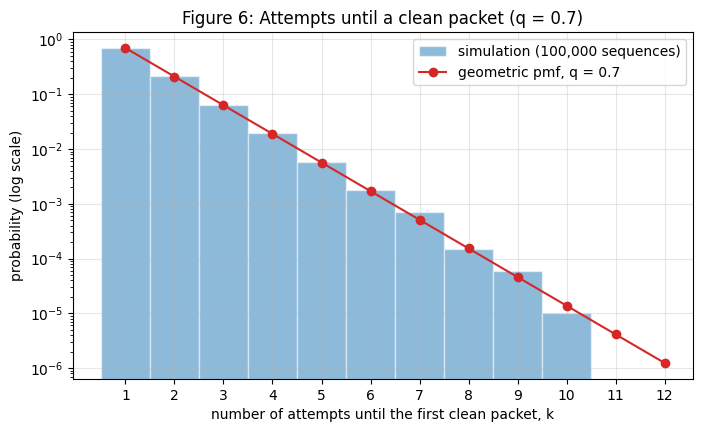

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Histogram as a density, with unit-width bins centred on each integer k
bins = np.arange(0.5, attempts6.max() + 1.5)
ax.hist(attempts6, bins=bins, density=True, log=True, color="C0", alpha=0.5,
        edgecolor="white", label=f"simulation ({N6:,} sequences)")

# Exact geometric pmf
k_values = np.arange(1, attempts6.max() + 3)
ax.plot(k_values, stats.geom.pmf(k_values, q6), "o-", color="C3", label="geometric pmf, q = 0.7")

ax.set_xticks(k_values)
ax.set_xlabel("number of attempts until the first clean packet, k")
ax.set_ylabel("probability (log scale)")
ax.set_title("Figure 6: Attempts until a clean packet (q = 0.7)")
ax.legend()
plt.show()

**What Figure 6 shows.** The simulated bars sit on the geometric pmf. On the log axis the pmf is a straight line, because each extra attempt multiplies the probability by $1 - q = 0.3$, a drop of about half a decade per attempt. The table confirms the match: for $k = 1$ to $6$, the largest difference between simulation and pmf is 1.16 standard errors. The bars at the far right are ragged only because so few sequences reach them: about 5 of the 100,000 sequences need 9 attempts, so those bars carry roughly ±45% sampling noise, which the log axis exaggerates. Even with a 70% success rate per attempt, $0.3^3 = 2.7\%$ of packets need four or more attempts.

### 6.4 Sample mean and variance against the closed forms

The closed forms for the attempts convention are $E[T] = 1/q$ and $\operatorname{Var}(T) = (1-q)/q^2$.

In [31]:
mean_exact = 1 / q6
var_exact = (1 - q6) / q6**2
mean_sim, mean_sim_se = mean_and_se(attempts6)
var_sim, var_sim_se = var_and_se(attempts6)

rows = [
    ["mean", f"{mean_sim:.4f}", f"1/q = {mean_exact:.4f}", f"{mean_sim - mean_exact:+.4f}",
     f"{mean_sim_se:.4f}", f"{abs(mean_sim - mean_exact) / mean_sim_se:.2f}"],
    ["variance", f"{var_sim:.4f}", f"(1-q)/q² = {var_exact:.4f}", f"{var_sim - var_exact:+.4f}",
     f"{var_sim_se:.4f}", f"{abs(var_sim - var_exact) / var_sim_se:.2f}"],
]
show_table(["quantity", "simulated", "closed form", "difference", "SE", "|z|"], rows)

| quantity | simulated | closed form | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| mean | 1.4325 | 1/q = 1.4286 | +0.0039 | 0.0025 | 1.57 |
| variance | 0.6238 | (1-q)/q² = 0.6122 | +0.0115 | 0.0062 | 1.87 |

**Result.** The sample mean is 1.4325 against $1/q = 1.4286$, a difference of +0.0039 with a standard error of 0.0025 ($|z| = $ 1.57). The sample variance is 0.6238 against $(1-q)/q^2 = 0.6122$, a difference of +0.0115 with a standard error of 0.0062 ($|z| = $ 1.87). Both closed forms are confirmed, which reproduces the check-yourself values 1.4286 and 0.6122.

### 6.5 The memoryless property

If a packet has already failed $m$ times, the chance it needs more than $n$ further attempts is the same as for a brand-new packet:

$$P(T > m+n \mid T > m) = \frac{P(T > m+n)}{P(T > m)} = \frac{(1-q)^{m+n}}{(1-q)^{m}} = (1-q)^{n} = P(T > n).$$

With $n = 2$ the exact value is $0.3^2 = 0.09$. The estimates below reuse the 100,000 sequences from 6.3.

In [32]:
n = 2
p_more_than_n, se_n = prob_and_se(np.sum(attempts6 > n), N6)
print(f"P(T > {n}) = {p_more_than_n:.4f} (SE {se_n:.4f});  exact value (1 - q)^{n} = {(1 - q6) ** n:.4f}")

rows, z_values = [], []
for m in (1, 3, 5):
    already_failed = attempts6[attempts6 > m]          # sequences whose first m attempts all failed
    p_cond, se_cond = prob_and_se(np.sum(already_failed > m + n), len(already_failed))
    diff = p_cond - p_more_than_n
    se_diff = np.sqrt(se_cond**2 + se_n**2)            # approximate: the two estimates share some samples
    z_values.append(abs(diff) / se_diff)
    rows.append([f"({m}, {n})", f"{len(already_failed):,}", f"{p_cond:.4f}", f"{se_cond:.4f}",
                 f"{diff:+.4f}", f"{se_diff:.4f}", f"{z_values[-1]:.2f}"])

show_table(["(m, n)", "sequences with T > m", "P(T > m+n | T > m)", "SE",
            "difference from P(T > n)", "SE of difference", "|z|"], rows)
report_largest_z(z_values)

P(T > 2) = 0.0906 (SE 0.0009);  exact value (1 - q)^2 = 0.0900


| (m, n) | sequences with T > m | P(T > m+n \| T > m) | SE | difference from P(T > n) | SE of difference | \|z\| |
|:---|---:|---:|---:|---:|---:|---:|
| (1, 2) | 30,168 | 0.0921 | 0.0017 | +0.0015 | 0.0019 | 0.82 |
| (3, 2) | 2,779 | 0.0993 | 0.0057 | +0.0087 | 0.0057 | 1.52 |
| (5, 2) | 276 | 0.0797 | 0.0163 | -0.0109 | 0.0163 | 0.67 |

Largest |z| = 1.52  ->  all within 3 standard errors: True


**Result.** All three conditional probabilities match $P(T > 2)$, with differences of 0.82, 1.52 and 0.67 standard errors for $m = 1$, 3 and 5. The standard error grows with $m$ because conditioning on $T > m$ keeps only a fraction $0.3^m$ of the sequences: 30,168 sequences for $m = 1$, but only 276 for $m = 5$. The $(5, 2)$ check is therefore about ten times noisier than the $(1, 2)$ check. That is the price of conditioning on a rare event, not a failure of memorylessness.

### 6.6 Why five failures don't change the odds of the sixth attempt

In the model, every attempt is a fresh, independent pass through a channel with the same $p$, so the sixth attempt succeeds with probability $q$ exactly like the first, and the five failures carry no information about it. The assumption doing the work is that the channel is independent and identically distributed from one attempt to the next; on a real radio link, fading, shadowing and interference stay correlated over the channel's coherence time, so a run of failures means the link is probably in a bad state right now and an immediate retry is *less* likely to succeed, which is why practical retransmission schemes back off or change frequency before retrying.

## Step 7: Expectation, variance, and how fast estimates settle

This step measures how quickly a running average settles on the true mean. It uses one case from Step 4 and one from Step 6, and repeats each experiment 200 times.

| case | what is counted | mean $\mu$ | variance $\sigma^2$ | $\sigma$ |
|---|---|---|---|---|
| Binomial (Step 4) | bit errors in a 1000-bit packet, $p = 0.005$ | $np = 5$ | $np(1-p) = 4.975$ | 2.2305 |
| Geometric (Step 6) | attempts until a clean packet, $q = 0.7$ | $1/q = 1.4286$ | $(1-q)/q^2 = 0.6122$ | 0.7825 |

**What theory predicts.** The running mean after $N$ trials is $\bar X_N = \frac{1}{N}\sum_{i=1}^{N} X_i$. Because the trials are independent, their variances add:

$$\operatorname{Var}(\bar X_N) = \frac{1}{N^2}\sum_{i=1}^{N}\operatorname{Var}(X_i) = \frac{\sigma^2}{N}, \qquad \operatorname{SD}(\bar X_N) = \frac{\sigma}{\sqrt N}.$$

So the spread across runs should shrink like $1/\sqrt N$: ten times more trials gives only about three times ($\sqrt{10}$) the precision. By the central limit theorem, about 95% of runs should land within $\mu \pm 1.96\,\sigma/\sqrt N$.

**How the runs are stored.** Each run draws $10^5$ samples, records the running mean at 30 checkpoints, and discards the samples. Each case therefore stores a $200 \times 30$ array, never $200 \times 10^5$.

In [33]:
N_RUNS = 200
checkpoints = np.unique(np.round(np.logspace(1, 5, 30)).astype(int))   # 30 values of N, from 10 to 100,000


def running_means(draw):
    """Repeat an experiment N_RUNS times and return the running mean at each checkpoint.

    draw(n) must return n fresh samples. Each run keeps only its 30 checkpoint
    values, so the result has shape (N_RUNS, 30), not (N_RUNS, 100000).
    """
    result = np.empty((N_RUNS, len(checkpoints)))
    for run in range(N_RUNS):
        samples = draw(checkpoints[-1])                # 100,000 fresh samples for this run
        running_sum = np.cumsum(samples)
        result[run] = running_sum[checkpoints - 1] / checkpoints
    return result                                      # the samples are discarded here


def draw_binomial(n):
    """Bit errors in each of n packets of 1000 bits, p = 0.005 (Step 4)."""
    return packet_errors(n, 1000, 0.005, rng7)


def draw_geometric(n):
    """Attempts until a clean packet, for n packets with q = 0.7 (Step 6)."""
    return attempts_until_clean(n, 0.7, rng7)


t0 = time.perf_counter()
binomial_runs = running_means(draw_binomial)
geometric_runs = running_means(draw_geometric)
print(f"Stored array per case: {binomial_runs.shape}   (both cases took {time.perf_counter() - t0:.1f} s)")

Stored array per case: (200, 30)   (both cases took 1.4 s)


### 7.3–7.4 Spread of the 200 runs and the $1/\sqrt N$ curve

The shaded band in Figure 7 holds the central 95% of the 200 running means at each checkpoint. Two numbers test whether it follows $1/\sqrt N$:

- the slope of the band's half-width against $N$ on log-log axes, which should be $-0.5$;
- the constant $k$ in "half-width $= k/\sqrt N$", matched to the band at one checkpoint (the one nearest $N = 1000$), which the CLT says should be $1.96\,\sigma$.

In [34]:
def band_95(runs):
    """Central 95% of the runs at each checkpoint: returns (lower edge, upper edge, half-width).
    method="median_unbiased" avoids the slight inward bias numpy's default
    percentile has when there are only 200 runs."""
    lower, upper = np.percentile(runs, [2.5, 97.5], axis=0, method="median_unbiased")
    return lower, upper, (upper - lower) / 2


anchor = np.argmin(np.abs(np.log(checkpoints / 1000)))     # index of the checkpoint nearest N = 1000

cases = {
    #             runs            true mean  true sigma
    "Binomial":  (binomial_runs,  5.0,       np.sqrt(4.975)),
    "Geometric": (geometric_runs, 1 / 0.7,   np.sqrt(0.3 / 0.7**2)),
}

bands = {}
shape_rows, final_rows = [], []
for name, (runs, mu, sigma) in cases.items():
    lower, upper, half = band_95(runs)
    slope = np.polyfit(np.log(checkpoints), np.log(half), 1)[0]      # should be -0.5
    k_matched = half[anchor] * np.sqrt(checkpoints[anchor])           # half-width = k / sqrt(N) at the anchor
    final_mean, final_se = mean_and_se(runs[:, -1])                   # the 200 estimates at N = 100,000
    bands[name] = dict(runs=runs, mu=mu, sigma=sigma, lower=lower, upper=upper, half=half, k=k_matched)

    shape_rows.append([name, f"{slope:+.3f}", f"{k_matched:.3f}", f"{Z95 * sigma:.3f}",
                       f"{100 * (k_matched / (Z95 * sigma) - 1):+.1f}%"])
    final_rows.append([name, f"{final_mean:.4f}", f"{mu:.4f}", f"{final_mean - mu:+.1e}",
                       f"{final_se:.1e}", f"{abs(final_mean - mu) / final_se:.2f}"])

show_table(["case", "log-log slope (theory: −0.5)", f"k matched at N = {checkpoints[anchor]:,}",
            "CLT: k = 1.96σ", "k vs CLT"], shape_rows)
show_table(["case", "mean of the 200 runs at N = 10⁵", "true mean", "difference", "SE", "|z|"], final_rows)

| case | log-log slope (theory: −0.5) | k matched at N = 1,172 | CLT: k = 1.96σ | k vs CLT |
|:---|---:|---:|---:|---:|
| Binomial | -0.491 | 4.317 | 4.372 | -1.2% |
| Geometric | -0.495 | 1.567 | 1.534 | +2.2% |

| case | mean of the 200 runs at N = 10⁵ | true mean | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| Binomial | 5.0003 | 5.0000 | +2.6e-04 | 5.3e-04 | 0.49 |
| Geometric | 1.4284 | 1.4286 | -1.8e-04 | 1.8e-04 | 1.05 |

In [35]:
# 7.5: how many trials until the Binomial running mean is within 1% of the true mean in 95% of runs?
binom_band = bands["Binomial"]
tolerance = 0.01 * binom_band["mu"]                        # 1% of 5 = 0.05 errors per packet

last_wider = np.nonzero(binom_band["half"] > tolerance)[0][-1]    # last checkpoint where the band is wider than ±1%
N_lo, N_hi = checkpoints[last_wider], checkpoints[last_wider + 1]
h_lo, h_hi = binom_band["half"][last_wider], binom_band["half"][last_wider + 1]

# Straight-line interpolation on log-log axes between those two checkpoints
fraction = np.log(h_lo / tolerance) / np.log(h_lo / h_hi)
N_needed = N_lo * (N_hi / N_lo) ** fraction
N_clt = (Z95 * binom_band["sigma"] / tolerance) ** 2       # CLT: 1.96 sigma / sqrt(N) = 0.01 mu

print(f"Band is wider than ±1% at N = {N_lo:,} and narrower from N = {N_hi:,} on")
print(f"Interpolated crossing: N ≈ {N_needed:,.0f}   (CLT prediction: {N_clt:,.0f})")

Band is wider than ±1% at N = 5,736 and narrower from N = 7,880 on
Interpolated crossing: N ≈ 6,704   (CLT prediction: 7,645)


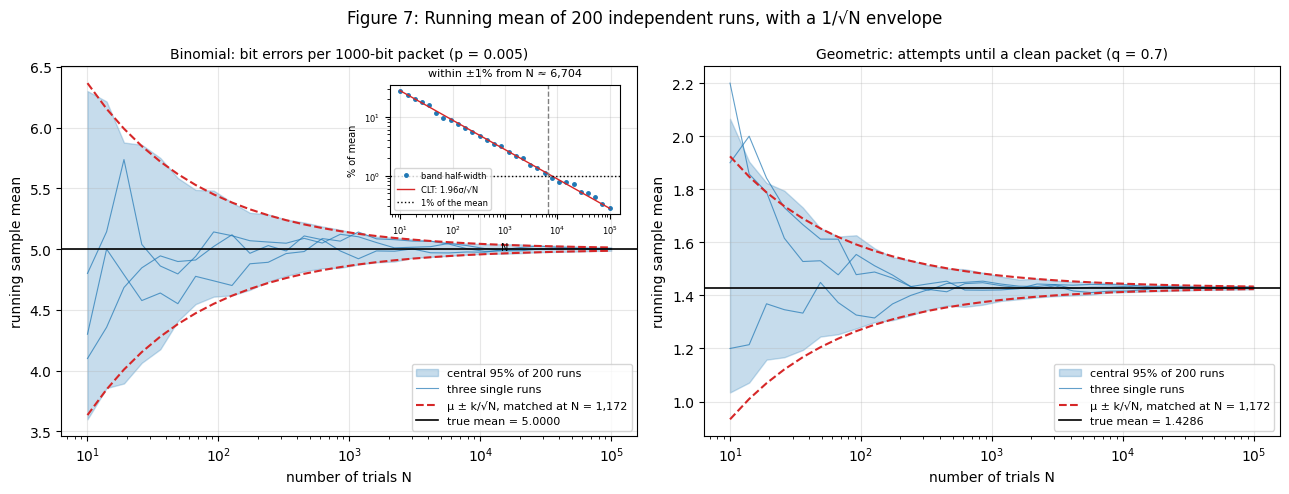

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name in zip(axes, ["Binomial", "Geometric"]):
    b = bands[name]
    envelope = b["k"] / np.sqrt(checkpoints)

    ax.fill_between(checkpoints, b["lower"], b["upper"], color="C0", alpha=0.25,
                    label="central 95% of 200 runs")
    for run in range(3):                               # a few single runs for reference
        ax.plot(checkpoints, b["runs"][run], color="C0", lw=0.8, alpha=0.7,
                label="three single runs" if run == 0 else None)
    ax.plot(checkpoints, b["mu"] + envelope, "--", color="C3",
            label=f"μ ± k/√N, matched at N = {checkpoints[anchor]:,}")
    ax.plot(checkpoints, b["mu"] - envelope, "--", color="C3")
    ax.axhline(b["mu"], color="k", lw=1.2, label=f"true mean = {b['mu']:.4f}")

    ax.set_xscale("log")
    ax.set_xlabel("number of trials N")
    ax.set_ylabel("running sample mean")
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_title("Binomial: bit errors per 1000-bit packet (p = 0.005)", fontsize=10)
axes[1].set_title("Geometric: attempts until a clean packet (q = 0.7)", fontsize=10)

# Inset on the Binomial panel: band half-width as a percentage of the mean, against the 1% target
inset = axes[0].inset_axes([0.57, 0.6, 0.4, 0.35])
inset.loglog(checkpoints, 100 * binom_band["half"] / binom_band["mu"], "o", ms=2.5, label="band half-width")
inset.loglog(checkpoints, 100 * Z95 * binom_band["sigma"] / np.sqrt(checkpoints) / binom_band["mu"],
             color="C3", lw=1, label="CLT: 1.96σ/√N")
inset.axhline(1, color="k", ls=":", lw=1, label="1% of the mean")
inset.axvline(N_needed, color="gray", ls="--", lw=1)
inset.set_title(f"within ±1% from N ≈ {N_needed:,.0f}", fontsize=8)
inset.set_xlabel("N", fontsize=7)
inset.set_ylabel("% of mean", fontsize=7)
inset.tick_params(labelsize=6)
inset.legend(fontsize=6, loc="lower left")

fig.suptitle("Figure 7: Running mean of 200 independent runs, with a 1/√N envelope")
fig.tight_layout()
plt.show()

**What Figure 7 shows.** In both panels, single runs wander for the first few hundred trials and then settle, while the shaded band holding the central 95% of the 200 runs narrows toward the true mean.

**7.4 Does the spread follow $1/\sqrt N$?** Yes. On log-log axes the band's half-width falls with a slope of -0.491 for the Binomial case and -0.495 for the geometric case, against $-0.5$ for $1/\sqrt N$. The dashed curve, scaled to match the band at $N = 1{,}172$, tracks the band across four decades of $N$, and its constant $k$ is 4.317 for the Binomial case and 1.567 for the geometric case, against the CLT values $1.96\,\sigma = 4.372$ and $1.534$ (-1.2% and +2.2%). The band itself is estimated from only 200 runs, so it wobbles by several percent from checkpoint to checkpoint, and small gaps between it and the dashed curve are expected. In practical terms, every extra decimal digit of accuracy costs 100 times more trials. The geometric band is lopsided at small $N$, reaching farther above the mean than below, because the geometric distribution is skewed to the right; that skew fades like $1/\sqrt N$, so after a few hundred trials the band is symmetric.

### 7.5 How many trials for 1% accuracy?

For the Binomial case, 1% of the mean is $\pm 0.05$ errors per packet. The inset in Figure 7 plots the band's half-width as a percentage of the mean. It is still wider than 1% at $N = $ 5,736 and narrower from $N = $ 7,880 on, and interpolating between those two checkpoints puts the crossing at $N \approx$ 6,704. The CLT gives a prediction to compare against:

$$1.96\,\frac{\sigma}{\sqrt N} \le 0.01\,\mu \quad\Longrightarrow\quad N \ge \left(\frac{1.96 \times 2.2305}{0.05}\right)^2 \approx 7{,}645.$$

The two agree to within about 12%. That is the size of error to expect here: the required $N$ scales with the square of the band's width, so the few-percent uncertainty of a band built from only 200 runs roughly doubles in $N$.

**Answer:** about 8,000 trials. The band is inside $\pm 1\%$ by $N = $ 7,880, and the CLT puts the requirement at about 7,600, so roughly 8,000 trials (order $10^4$) give the sample mean of the Binomial case a 95% chance of being within 1% of the true mean. Step 4's run of $10^5$ packets is well past that, with a 95% band of about $\pm 0.3\%$.

## Step 8: Throughput of the link

### 8.1 Probability that a packet arrives clean

The number of bit errors in an $n$-bit packet is $K \sim \text{Binomial}(n, p)$ (Step 4). A packet is clean when $K = 0$:

$$q(p) = P(K = 0) = \binom{n}{0}\,p^0\,(1-p)^{n} = (1-p)^{n}, \qquad n = 1000.$$

### 8.2 Expected transmissions per delivered packet

Attempts are independent and each one is clean with probability $q(p)$, so the number of transmissions is geometric (Step 6), and

$$E[T] = \frac{1}{q(p)} = (1-p)^{-n}.$$

In [37]:
N_BITS = 1000


def p_clean(p, n=N_BITS):
    """Probability that an n-bit packet has no bit errors: (1 - p)^n."""
    return (1 - np.asarray(p, dtype=float)) ** n


def expected_tx(p, n=N_BITS):
    """Expected transmissions per delivered packet: 1 / (1 - p)^n."""
    return 1 / p_clean(p, n)


def goodput(p, n=N_BITS):
    """Delivered bits / transmitted bits = 1 / E[T] = (1 - p)^n  (derived in 8.6)."""
    return p_clean(p, n)


print(f"At p = 1e-2: q = {p_clean(1e-2):.2e}, so E[T] = {expected_tx(1e-2):,.0f} transmissions per delivered packet")

At p = 1e-2: q = 4.32e-05, so E[T] = 23,164 transmissions per delivered packet


### 8.5 Where the link needs more than 2 transmissions

$$E[T] > 2 \iff (1-p)^{-n} > 2 \iff -n\ln(1-p) > \ln 2 \iff \ln(1-p) < -\frac{\ln 2}{n} \iff p > 1 - 2^{-1/n}.$$

For $n = 1000$: $p = 1 - 2^{-1/1000} = 6.93\times10^{-4}$. Because $\ln 2/n$ is small, this is approximately $\ln 2/n$.

### 8.6 Goodput

Suppose $M$ packets are delivered and packet $i$ takes $T_i$ attempts. Every attempt sends $n$ bits, and every delivered packet carries $n$ bits, so

$$\text{goodput} = \frac{\text{delivered bits}}{\text{transmitted bits}} = \frac{nM}{n\sum_{i=1}^{M} T_i} = \frac{1}{\bar T} \;\longrightarrow\; \frac{1}{E[T]} = (1-p)^{n} \quad\text{as } M \to \infty.$$

Goodput equals the probability that a packet arrives clean: every attempt costs a full packet, and only clean attempts deliver anything. To keep goodput at or above 90%:

$$(1-p)^{n} \ge 0.9 \iff p \le 1 - 0.9^{1/n} \approx \frac{-\ln 0.9}{n} = \frac{0.105}{n}.$$

For $n = 1000$ that is $p \le 1.05\times10^{-4}$, or at most $1/0.9 = 1.11$ transmissions per packet on average.

In [38]:
def p_for_expected_tx(target, n=N_BITS):
    """Bit error probability at which E[T] = target:  p = 1 - target^(-1/n)."""
    return 1 - target ** (-1 / n)


def p_for_goodput(target, n=N_BITS):
    """Bit error probability at which goodput = target:  p = 1 - target^(1/n)."""
    return 1 - target ** (1 / n)


p_two_tx = p_for_expected_tx(2)
p_90 = p_for_goodput(0.9)
print(f"E[T] = 2 at p = {p_two_tx:.3e}         (check: E[T] there = {expected_tx(p_two_tx):.4f})")
print(f"Goodput = 0.90 at p = {p_90:.3e}   (check: goodput there = {goodput(p_90):.4f})")

E[T] = 2 at p = 6.929e-04         (check: E[T] there = 2.0000)
Goodput = 0.90 at p = 1.054e-04   (check: goodput there = 0.9000)


### 8.3–8.4 Analytic curve and simulated points

The curves use the exact formulas from $p = 10^{-5}$ to $10^{-2}$. Each of the five simulated points (from $10^{-5}$ to $10^{-3}$) gives `attempts_until_clean` the exact clean probability $q(p)$ and draws 100,000 delivered packets, so no individual bits are simulated. Simulated goodput is (packets delivered) / (total attempts), and its standard error comes from the delta method, $\mathrm{SE}(1/\bar T) \approx \mathrm{SE}(\bar T)/\bar T^{\,2}$.

In [39]:
N8 = 100_000                          # delivered packets per simulated point
p_sim = np.logspace(-5, -3, 5)        # 1e-5, 3.2e-5, 1e-4, 3.2e-4, 1e-3


def simulate_link(p_values, n_bits, rng):
    """Simulate N8 delivered packets at each p, using the exact clean probability
    (no bit-level simulation). Returns four arrays: mean transmissions, its SE,
    goodput (= 1 / mean transmissions), and the goodput SE (delta method)."""
    tx_mean, tx_se = [], []
    for p in p_values:
        attempts = attempts_until_clean(N8, p_clean(p, n_bits), rng)
        mean, se = mean_and_se(attempts)
        tx_mean.append(mean)
        tx_se.append(se)
    tx_mean, tx_se = np.array(tx_mean), np.array(tx_se)
    return tx_mean, tx_se, 1 / tx_mean, tx_se / tx_mean**2


tx_sim, tx_se, gp_sim, gp_se = simulate_link(p_sim, N_BITS, rng8)

# Expected transmissions: simulation against the exact formula
rows, z_values = [], []
for p, sim, se in zip(p_sim, tx_sim, tx_se):
    exact = expected_tx(p)
    z_values.append(abs(sim - exact) / se)
    rows.append([f"{p:.2e}", f"{exact:.5f}", f"{sim:.5f}", f"{sim - exact:+.1e}", f"{se:.1e}", f"{z_values[-1]:.2f}"])
show_table(["p", "E[T] exact", "E[T] simulated", "difference", "SE", "|z|"], rows)

# Goodput: same draws, so each |z| matches the row above
rows = []
for p, sim, se in zip(p_sim, gp_sim, gp_se):
    exact = goodput(p)
    rows.append([f"{p:.2e}", f"{exact:.5f}", f"{sim:.5f}", f"{sim - exact:+.1e}", f"{se:.1e}",
                 f"{abs(sim - exact) / se:.2f}"])
show_table(["p", "goodput exact", "goodput simulated", "difference", "SE", "|z|"], rows)
report_largest_z(z_values)

| p | E[T] exact | E[T] simulated | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1.00e-05 | 1.01005 | 1.00976 | -2.9e-04 | 3.1e-04 | 0.92 |
| 3.16e-05 | 1.03213 | 1.03255 | +4.2e-04 | 5.8e-04 | 0.73 |
| 1.00e-04 | 1.10518 | 1.10629 | +1.1e-03 | 1.1e-03 | 1.02 |
| 3.16e-04 | 1.37201 | 1.37216 | +1.5e-04 | 2.3e-03 | 0.07 |
| 1.00e-03 | 2.71964 | 2.71506 | -4.6e-03 | 6.8e-03 | 0.67 |

| p | goodput exact | goodput simulated | difference | SE | \|z\| |
|:---|---:|---:|---:|---:|---:|
| 1.00e-05 | 0.99005 | 0.99033 | +2.8e-04 | 3.1e-04 | 0.92 |
| 3.16e-05 | 0.96887 | 0.96848 | -4.0e-04 | 5.5e-04 | 0.73 |
| 1.00e-04 | 0.90483 | 0.90392 | -9.1e-04 | 8.9e-04 | 1.02 |
| 3.16e-04 | 0.72886 | 0.72878 | -7.9e-05 | 1.2e-03 | 0.07 |
| 1.00e-03 | 0.36770 | 0.36832 | +6.2e-04 | 9.3e-04 | 0.67 |

Largest |z| = 1.02  ->  all within 3 standard errors: True


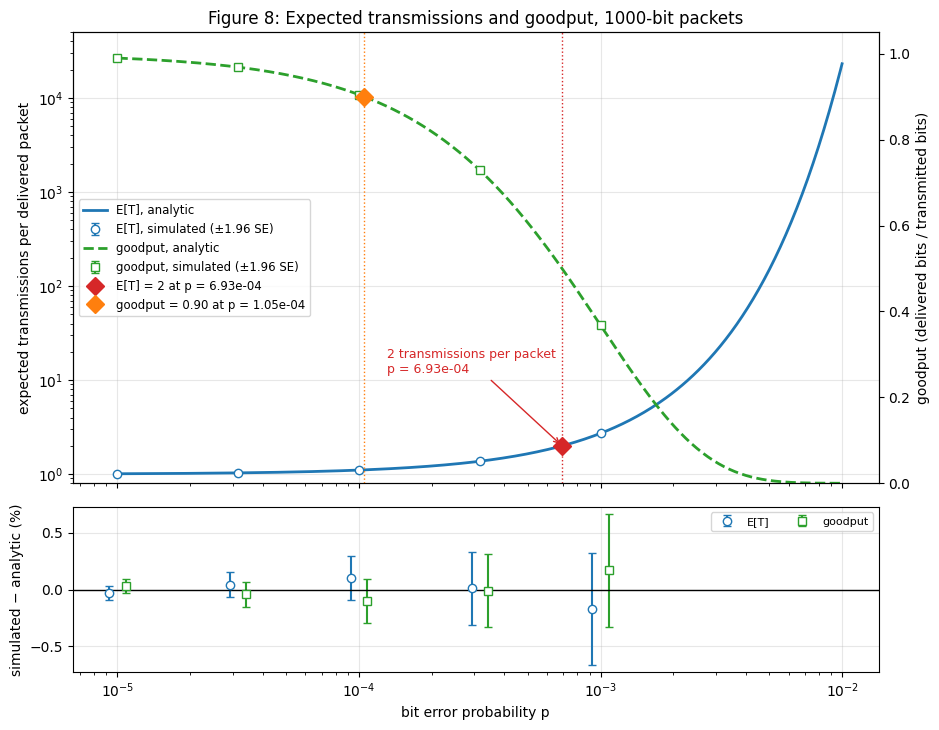

In [40]:
p_grid = np.logspace(-5, -2, 400)     # p values for the analytic curves

fig, (ax, ax_resid) = plt.subplots(2, 1, figsize=(9.5, 7.4), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1.1]})
ax_gp = ax.twinx()                    # right-hand axis for goodput

# Expected transmissions (left axis, log scale)
tx_line, = ax.plot(p_grid, expected_tx(p_grid), color="C0", lw=2, label="E[T], analytic")
tx_points = ax.errorbar(p_sim, tx_sim, yerr=Z95 * tx_se, fmt="o", mfc="white", color="C0",
                        capsize=3, label="E[T], simulated (±1.96 SE)")
tx_mark, = ax.plot(p_two_tx, 2, "D", color="C3", ms=9, zorder=5,
                   label=f"E[T] = 2 at p = {p_two_tx:.2e}")
ax.axvline(p_two_tx, color="C3", ls=":", lw=1)
ax.annotate(f"2 transmissions per packet\np = {p_two_tx:.2e}", xy=(p_two_tx, 2), xytext=(1.3e-4, 12),
            color="C3", fontsize=9, arrowprops={"arrowstyle": "->", "color": "C3"})

# Goodput (right axis, linear scale)
gp_line, = ax_gp.plot(p_grid, goodput(p_grid), color="C2", lw=2, ls="--", label="goodput, analytic")
gp_points = ax_gp.errorbar(p_sim, gp_sim, yerr=Z95 * gp_se, fmt="s", mfc="white", color="C2",
                           capsize=3, label="goodput, simulated (±1.96 SE)")
gp_mark, = ax_gp.plot(p_90, 0.9, "D", color="C1", ms=9, zorder=5,
                      label=f"goodput = 0.90 at p = {p_90:.2e}")
ax_gp.axvline(p_90, color="C1", ls=":", lw=1)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(0.8, 5e4)
ax_gp.set_ylim(0, 1.05)
ax_gp.grid(False)
ax.set_ylabel("expected transmissions per delivered packet")
ax_gp.set_ylabel("goodput (delivered bits / transmitted bits)")
ax.set_title("Figure 8: Expected transmissions and goodput, 1000-bit packets")
ax_gp.legend(handles=[tx_line, tx_points, gp_line, gp_points, tx_mark, gp_mark],
             loc="center left", fontsize=8.5)

# Lower panel: simulated minus analytic, in percent, with 95% error bars
tx_exact, gp_exact = expected_tx(p_sim), goodput(p_sim)
ax_resid.errorbar(p_sim / 1.08, 100 * (tx_sim / tx_exact - 1), yerr=100 * Z95 * tx_se / tx_exact,
                  fmt="o", mfc="white", color="C0", capsize=3, label="E[T]")
ax_resid.errorbar(p_sim * 1.08, 100 * (gp_sim / gp_exact - 1), yerr=100 * Z95 * gp_se / gp_exact,
                  fmt="s", mfc="white", color="C2", capsize=3, label="goodput")
ax_resid.axhline(0, color="k", lw=1)
ax_resid.set_xlabel("bit error probability p")
ax_resid.set_ylabel("simulated − analytic (%)")
ax_resid.legend(fontsize=8, ncol=2, loc="upper right")

fig.tight_layout()
plt.show()

**What Figure 8 shows.** Expected transmissions stay near 1 while the expected number of bit errors per packet, $np$, is small, and then climb steeply. Because $E[T] = (1-p)^{-1000} \approx e^{1000p}$ grows exponentially in $p$, the curve bends upward like a wall on log-log axes instead of following a straight line. It crosses 2 transmissions at $p = 6.93\times10^{-4}$ (red diamond) and reaches about 23,000 at $p = 10^{-2}$. Goodput is the mirror image, $1/E[T]$: 0.99 at $10^{-5}$, 0.90 at $1.05\times10^{-4}$ (orange diamond) and 0.37 at $10^{-3}$.

The five simulated points sit on both curves, and the largest difference is 1.02 standard errors (tables above). On these axes the 95% error bars are smaller than the markers, since the relative standard errors are below 0.3%, so the lower panel shows the differences in percent.

**8.4 Why the curve can be trusted out to $10^{-2}$ without simulating there.** The formula follows exactly from the model's two assumptions (independent bit errors within a packet and independent attempts), neither of which depends on $p$ or involves an approximation that gets worse as $p$ grows, so once the simulations confirm it at small $p$ it holds at every $p$.

### 8.7 Effect of packet length

The table gives both thresholds for 100-, 1000- and 10000-bit packets. Figure 9 repeats Figure 8 for all three lengths, with five simulated points per length.

In [41]:
lengths = [100, 1000, 10000]

rows = []
for n in lengths:
    rows.append([f"{n:,}", f"{p_for_expected_tx(2, n):.3e}", f"{p_for_goodput(0.9, n):.3e}",
                 f"{n * p_for_goodput(0.9, n):.4f}"])
show_table(["packet length n (bits)", "p where E[T] = 2", "p where goodput = 0.90",
            "n × p (goodput = 0.90)"], rows)

# Simulated points for each length, and their agreement with the exact formula
sim9 = {n: simulate_link(p_sim, n, rng8) for n in lengths}
z_values = []
for n in lengths:
    tx, se, _, _ = sim9[n]
    z_values += list(np.abs(tx - expected_tx(p_sim, n)) / se)
report_largest_z(z_values)

| packet length n (bits) | p where E[T] = 2 | p where goodput = 0.90 | n × p (goodput = 0.90) |
|:---|---:|---:|---:|
| 100 | 6.908e-03 | 1.053e-03 | 0.1053 |
| 1,000 | 6.929e-04 | 1.054e-04 | 0.1054 |
| 10,000 | 6.931e-05 | 1.054e-05 | 0.1054 |

Largest |z| = 2.53  ->  all within 3 standard errors: True


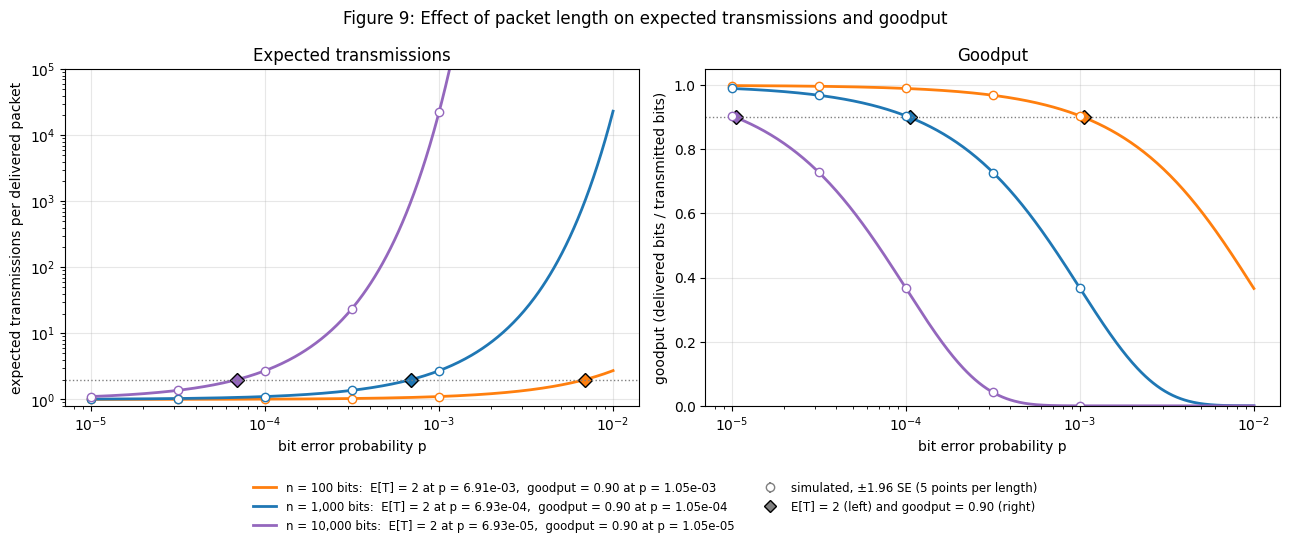

In [42]:
colors = {100: "C1", 1000: "C0", 10000: "C4"}

fig, (ax_tx, ax_gp) = plt.subplots(1, 2, figsize=(13, 5.4))
legend_handles = []
for n in lengths:
    color = colors[n]
    tx, tx_err, gp, gp_err = sim9[n]

    # Left panel: expected transmissions
    line, = ax_tx.plot(p_grid, expected_tx(p_grid, n), color=color, lw=2,
                       label=f"n = {n:,} bits:  E[T] = 2 at p = {p_for_expected_tx(2, n):.2e},  "
                             f"goodput = 0.90 at p = {p_for_goodput(0.9, n):.2e}")
    legend_handles.append(line)
    ax_tx.errorbar(p_sim, tx, yerr=Z95 * tx_err, fmt="o", mfc="white", color=color, capsize=2)
    ax_tx.plot(p_for_expected_tx(2, n), 2, "D", color=color, mec="k", ms=7)

    # Right panel: goodput
    ax_gp.plot(p_grid, goodput(p_grid, n), color=color, lw=2)
    ax_gp.errorbar(p_sim, gp, yerr=Z95 * gp_err, fmt="o", mfc="white", color=color, capsize=2)
    ax_gp.plot(p_for_goodput(0.9, n), 0.9, "D", color=color, mec="k", ms=7)

# Reference lines, plus gray legend entries for the two marker types
ax_tx.axhline(2, color="gray", ls=":", lw=1)
ax_gp.axhline(0.9, color="gray", ls=":", lw=1)
legend_handles.append(ax_tx.errorbar([], [], yerr=[], fmt="o", mfc="white", color="gray", capsize=2,
                                     label="simulated, ±1.96 SE (5 points per length)"))
legend_handles.append(ax_tx.plot([], [], "D", color="gray", mec="k", ls="none",
                                 label="E[T] = 2 (left) and goodput = 0.90 (right)")[0])

ax_tx.set(xscale="log", yscale="log", ylim=(0.8, 1e5), title="Expected transmissions",
          xlabel="bit error probability p", ylabel="expected transmissions per delivered packet")
ax_gp.set(xscale="log", ylim=(0, 1.05), title="Goodput",
          xlabel="bit error probability p", ylabel="goodput (delivered bits / transmitted bits)")
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=8.5, frameon=False)
fig.suptitle("Figure 9: Effect of packet length on expected transmissions and goodput")
fig.tight_layout(rect=[0, 0.13, 1, 1])
plt.show()

**What Figure 9 shows.** The three curves have the same shape and shift by one decade in $p$ for every factor of 10 in packet length. That happens because $E[T] = (1-p)^{-n} \approx e^{np}$ depends on $p$ almost entirely through $np$, the expected number of bit errors per packet, so the 90% goodput threshold lands at $np \approx -\ln 0.9 = 0.105$ for every length (last column of the table above). The 15 simulated points agree with the curves, with a largest difference of 2.53 standard errors.

**8.7 What the link needs.** With 1000-bit packets, the link must hold a bit error rate at or below about $1.05\times10^{-4}$ to keep goodput above 90%, which means averaging no more than 1.11 transmissions per delivered packet; past $6.9\times10^{-4}$ it averages more than two, and at $10^{-3}$ only 37% of the transmitted bits are useful. The tolerable bit error rate scales inversely with packet length, $p_{\max} \approx 0.105/n$, so 100-bit packets relax the requirement tenfold to about $1.05\times10^{-3}$, while 10000-bit packets tighten it tenfold to about $1.05\times10^{-5}$ (Figure 9). If the radio cannot hold $10^{-4}$, the levers are shorter packets or forward error correction (which raises the chance that a packet arrives clean), and 10000-bit packets only make sense on a link that holds $10^{-5}$ or better. Shorter packets are not free, though: each one carries a fixed header, so in practice the best packet length balances header overhead against the chance that a packet arrives clean.

## Summary of the check-yourself values

Every check-yourself value in the project specification, next to the value this notebook computes. Step 7 has no check-yourself values.

In [43]:
step1 = comparison.set_index("Event")
clean4 = clean_table4[clean_table4["p"] == 0.005].iloc[0]
le_cam5 = np.sqrt(0.01 / n5)
clean_se4 = np.sqrt(clean4["Exact P(clean)"] * (1 - clean4["Exact P(clean)"]) / n_pkt4)
summary = [
    ["1", "P(A) = 0.19", f"{step1.loc['A', 'Exact']:.4f}", f"{step1.loc['A', 'Estimated']:.4f}"],
    ["1", "P(B) = 0.0486", f"{step1.loc['B', 'Exact']:.4f}", f"{step1.loc['B', 'Estimated']:.4f}"],
    ["1", "P(C) = 0.1", f"{step1.loc['C', 'Exact']:.4f}", f"{step1.loc['C', 'Estimated']:.4f}"],
    ["1", "P(A ∪ B ∪ C) = 0.2710", f"{step1.loc['A | B | C', 'Exact']:.4f}", f"{step1.loc['A | B | C', 'Estimated']:.4f}"],
    ["2", "posterior about 0.045 at p = 0.001", f"{posterior_cases2[2]:.4f}", "–"],
    ["2", "crossover at p = 0.0206", f"{crossover_p2:.4f}", f"posterior {posterior_estimate2:.4f} at the crossover"],
    ["3", "conditional correlations zero within sampling error", "0",
     f"{receiver_table3.iloc[1]['Pearson r']:+.4f} and {receiver_table3.iloc[2]['Pearson r']:+.4f}"],
    ["4", "mean 5, variance 4.975", f"{theory_mean4:g}, {theory_variance4:g}",
     f"{errors4.mean():.4f}, {errors4.var(ddof=1):.4f}"],
    ["4", "P(clean) about 0.0067 at p = 0.005", f"{clean4['Exact P(clean)']:.5f}",
     f"{clean4['Empirical P(clean)']:.5f} ({abs(clean4['Difference']) / clean_se4:.1f} SE)"],
    ["5", "Le Cam bound reaches 0.01 at p = 0.0032", f"{le_cam5:.4f}", "–"],
    ["5", "bisection answer above 0.0032, about 10× higher", f"{p_limit5:.3f} ({p_limit5 / le_cam5:.1f}×)", "–"],
    ["6", "mean 1.4286, variance 0.6122", f"{mean_exact:.4f}, {var_exact:.4f}", f"{mean_sim:.4f}, {var_sim:.4f}"],
    ["8", "2 expected transmissions at p = 6.9 × 10⁻⁴", f"{p_two_tx:.3e}", "–"],
    ["8", "goodput 90% at p = 1.05 × 10⁻⁴", f"{p_90:.3e}", "–"],
]
show_table(["step", "check-yourself value", "this notebook (exact)", "this notebook (simulated)"], summary)

| step | check-yourself value | this notebook (exact) | this notebook (simulated) |
|:---|---:|---:|---:|
| 1 | P(A) = 0.19 | 0.1900 | 0.1906 |
| 1 | P(B) = 0.0486 | 0.0486 | 0.0487 |
| 1 | P(C) = 0.1 | 0.1000 | 0.1001 |
| 1 | P(A ∪ B ∪ C) = 0.2710 | 0.2710 | 0.2716 |
| 2 | posterior about 0.045 at p = 0.001 | 0.0454 | – |
| 2 | crossover at p = 0.0206 | 0.0206 | posterior 0.5013 at the crossover |
| 3 | conditional correlations zero within sampling error | 0 | +0.0020 and +0.0007 |
| 4 | mean 5, variance 4.975 | 5, 4.975 | 5.0018, 4.9799 |
| 4 | P(clean) about 0.0067 at p = 0.005 | 0.00665 | 0.00625 (1.6 SE) |
| 5 | Le Cam bound reaches 0.01 at p = 0.0032 | 0.0032 | – |
| 5 | bisection answer above 0.0032, about 10× higher | 0.040 (12.8×) | – |
| 6 | mean 1.4286, variance 0.6122 | 1.4286, 0.6122 | 1.4325, 0.6238 |
| 8 | 2 expected transmissions at p = 6.9 × 10⁻⁴ | 6.929e-04 | – |
| 8 | goodput 90% at p = 1.05 × 10⁻⁴ | 1.054e-04 | – |

In [44]:
print(f"Total runtime: {time.perf_counter() - started:.1f} s")

Total runtime: 10.4 s
